In [912]:
import numpy as np
import matplotlib.pyplot as plt
import corner
import scipy.special as sp
import scipy

plt.rcParams['figure.figsize'] = (20,10)

In [913]:
import time
from copy import deepcopy
import batoid
import dynesty
rstate= np.random.default_rng(56101)
#import multiprocessing
from scipy.special import jv
from scipy.special import j1
#from multiprocess import Pool

In [914]:
def telescopeCreation(WL,pdx,pdy,pdz,ptx,pty,sdx,sdy,sdz,stx,sty):
    #gaberration inputs in microns and arcseconds
    global telescope, M1

    global outter1, inner1, outterD
    
    K = 1000000 #meter to micron conversion
    A = 3600 #degree to arcsec conversion
    
    R1, conic1, inner1, outter1 = -16.256, -0.9953569, 1.38, 6.42
    #M1coord = defineCoordinate(anglX=0.0035, anglY=0.0035, anglZ=0, posX=200e-6, posY=200e-6, posZ=200e-6).local()
    M1coord = defineCoordinate(posX=pdx/K, posY=pdy/K, posZ=pdz/K, anglX=ptx/A, anglY=pty/A).local()
    M1 = optic('M1',type='Quadric', RoC=R1, conic=conic1, inDiam=inner1, outDiam=outter1, coordSys=M1coord).mirrorWithSpider(width=0.3, height=4)
                                                                                                                             
    R2, conic2, outter2 = -1.660575, -1.566503, 0.7147252
    #M2coord = defineCoordinate(anglX=-0.00878, anglY=0.0116, anglZ=0, posX=-0.2014e-3, posY=0.8984e-3, posZ=-7.400+191.3e-6).local()
    M2coord = defineCoordinate(posX=sdx/K, posY=sdy/K, posZ=-7.400+(sdz/K), anglX=stx/A, anglY=sty/A).local()
    M2 = optic('M2', type='Quadric', RoC=R2, conic=conic2, outDiam=outter2, coordSys=M2coord).mirror()

    R3, conic3, outter3 = -1.830517, -0.718069, 0.920733
    M3coord = defineCoordinate(posZ=+0.050).local()
    M3 = optic('M3', type='Quadric', RoC=R3, conic=conic3, outDiam=outter3, coordSys=M3coord).mirror()

    outter4 = 0.0991468
    M4coord = defineCoordinate(posZ=-0.983629).local()
    M4 = optic('M4', outDiam=outter4, coordSys=M4coord).flatMirror()

    outterD = 0.9
    Dcoord = defineCoordinate(posZ=0.237581).local()
    D = optic('D', outDiam=outterD, coordSys=Dcoord).detector()

    telescope = build.compoundOptic(M1, M2, M3, M4, D, 
                                    pupilSize=6.46, backDist=7.5,
                                    EPcoord=defineCoordinate(posZ=0).local())
    
    return telescope

In [915]:
%run Batoid4LOFT.ipynb

In [916]:
def _is_odd(integer):

    return integer & 1

def noll_indices(j):

    if j < 1:
        raise ValueError("Zernike index j must be a positive integer.")

    # from i, compute m and n
    # I'm not sure if there is an easier/cleaner algorithm or not.
    # This seems semi-complicated to me...

    # figure out which row of the triangle we're in (easy):
    n = int(np.ceil((-1 + np.sqrt(1 + 8 * j)) / 2) - 1)
    if n == 0:
        m = 0
    else:
        nprev = (n + 1) * (n + 2) / 2  # figure out which entry in the row (harder)
        # The rule is that the even Z obtain even indices j, the odd Z odd indices j.
        # Within a given n, lower values of m obtain lower j.

        resid = int(j - nprev - 1)

        if _is_odd(j):
            sign = -1
        else:
            sign = 1

        if _is_odd(n):
            row_m = [1, 1]
        else:
            row_m = [0]

        for i in range(int(np.floor(n / 2.))):
            row_m.append(row_m[-1] + 2)
            row_m.append(row_m[-1])

        m = row_m[resid] * sign

    return n, m

def circ_bessel(n, m, npix=128, rho=None, theta=None, outside=np.nan, zero=19.053609871416903, **kwargs):
 
    if theta is None and rho is None:
        x = (np.arange(npix, dtype=np.float64) - (npix - 1) / 2.) / (zero)
        y = x
        xx, yy = np.meshgrid(x, y)

        rho = np.sqrt(xx ** 2 + yy ** 2)
        theta = np.arctan2(yy, xx)
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")
        
    if not np.all(np.asarray(rho.shape == theta.shape)):
        raise ValueError('The rho and theta arrays do not have consistent shape.')

    if m == 0:
        if n == 0:
            cb_result = j1(2*np.pi*rho) * (1/rho)
        else:
            cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho)
    elif m > 0:
        cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho) * np.cos(np.abs(m) * theta)
    else:
        cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho) * np.sin(np.abs(m) * theta)
    return cb_result


def circ_bessel1(j, **kwargs):

    n, m = noll_indices(j)
    return circ_bessel(n, m, **kwargs)

In [7]:
def basis_vectors(nterms=15, npix=256, rho=None, theta=None, **kwargs):
    
    if rho is not None and theta is not None:
        # both are required, but validated in zernike1
        shape = rho.shape
        use_polar = True
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")

    else:
        shape = (npix, npix)
        use_polar = False

    basis_output = np.zeros((nterms,) + shape)

    if use_polar:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, rho=rho, theta=theta, **kwargs)
    else:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, npix=npix, **kwargs)
    return basis_output

In [8]:
def decompose_psf(psf, nterms=15, basis=basis_vectors, **kwargs):
    npix = psf.shape[0]
    basis_set = basis(nterms=nterms, npix=npix, outside=np.nan, **kwargs)
    basis_stack = np.stack(basis_set)  # shape: (nterms, npix, npix)
    psf_flat = psf.ravel()
    basis_flat = basis_stack.reshape(nterms, -1)
    numerators = np.dot(basis_flat, psf_flat)
    #numerators = ne.evaluate('sum(basis_flat*psf_flat)')
    denominators = np.einsum('ij,ij->i', basis_flat, basis_flat)
    #denominators = ne.evaluate('sum(basis_flat*basis_flat)')
    coeffs = numerators / denominators
    return coeffs

In [926]:
telescope = telescopeCreation(WL=650e-9, pdx=0, pdy=0, pdz=0, ptx=0, pty=0, sdx=0, sdy=0, sdz=0, stx=0, sty=0)
infoTelescope = details(telescope, fieldX=0, fieldY=0.17, wavelength=650e-9)
WF = infoTelescope.wavefront(npx=1024, background=False)

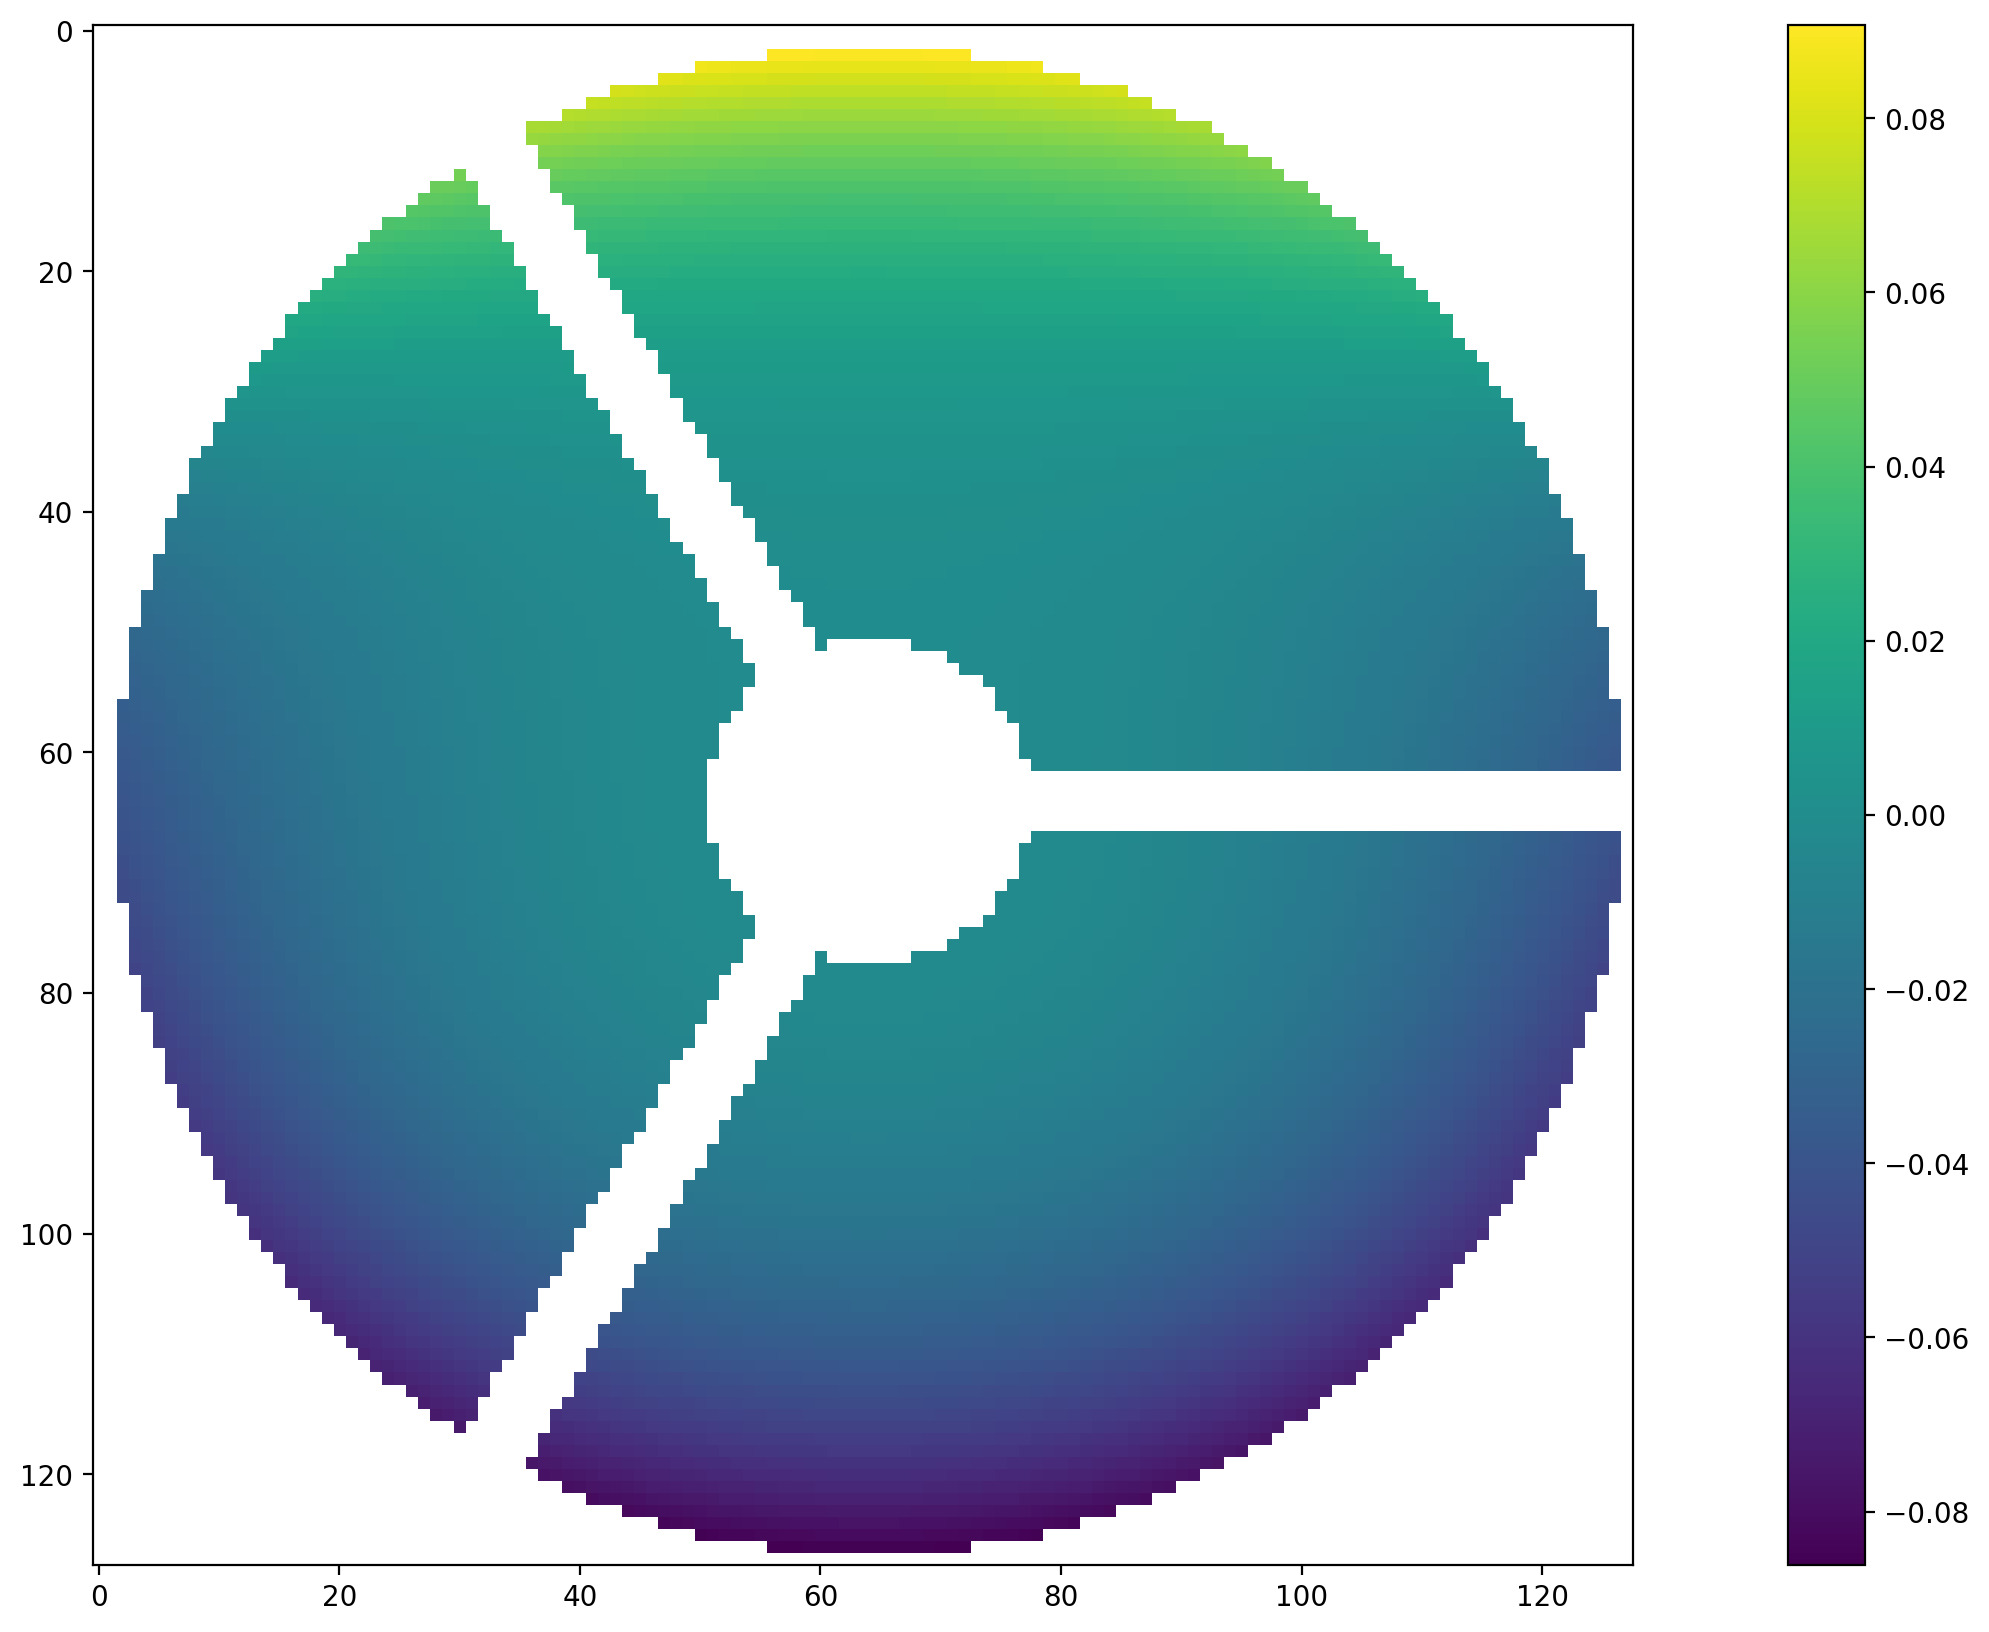

In [922]:
plt.imshow(WF)
plt.colorbar()

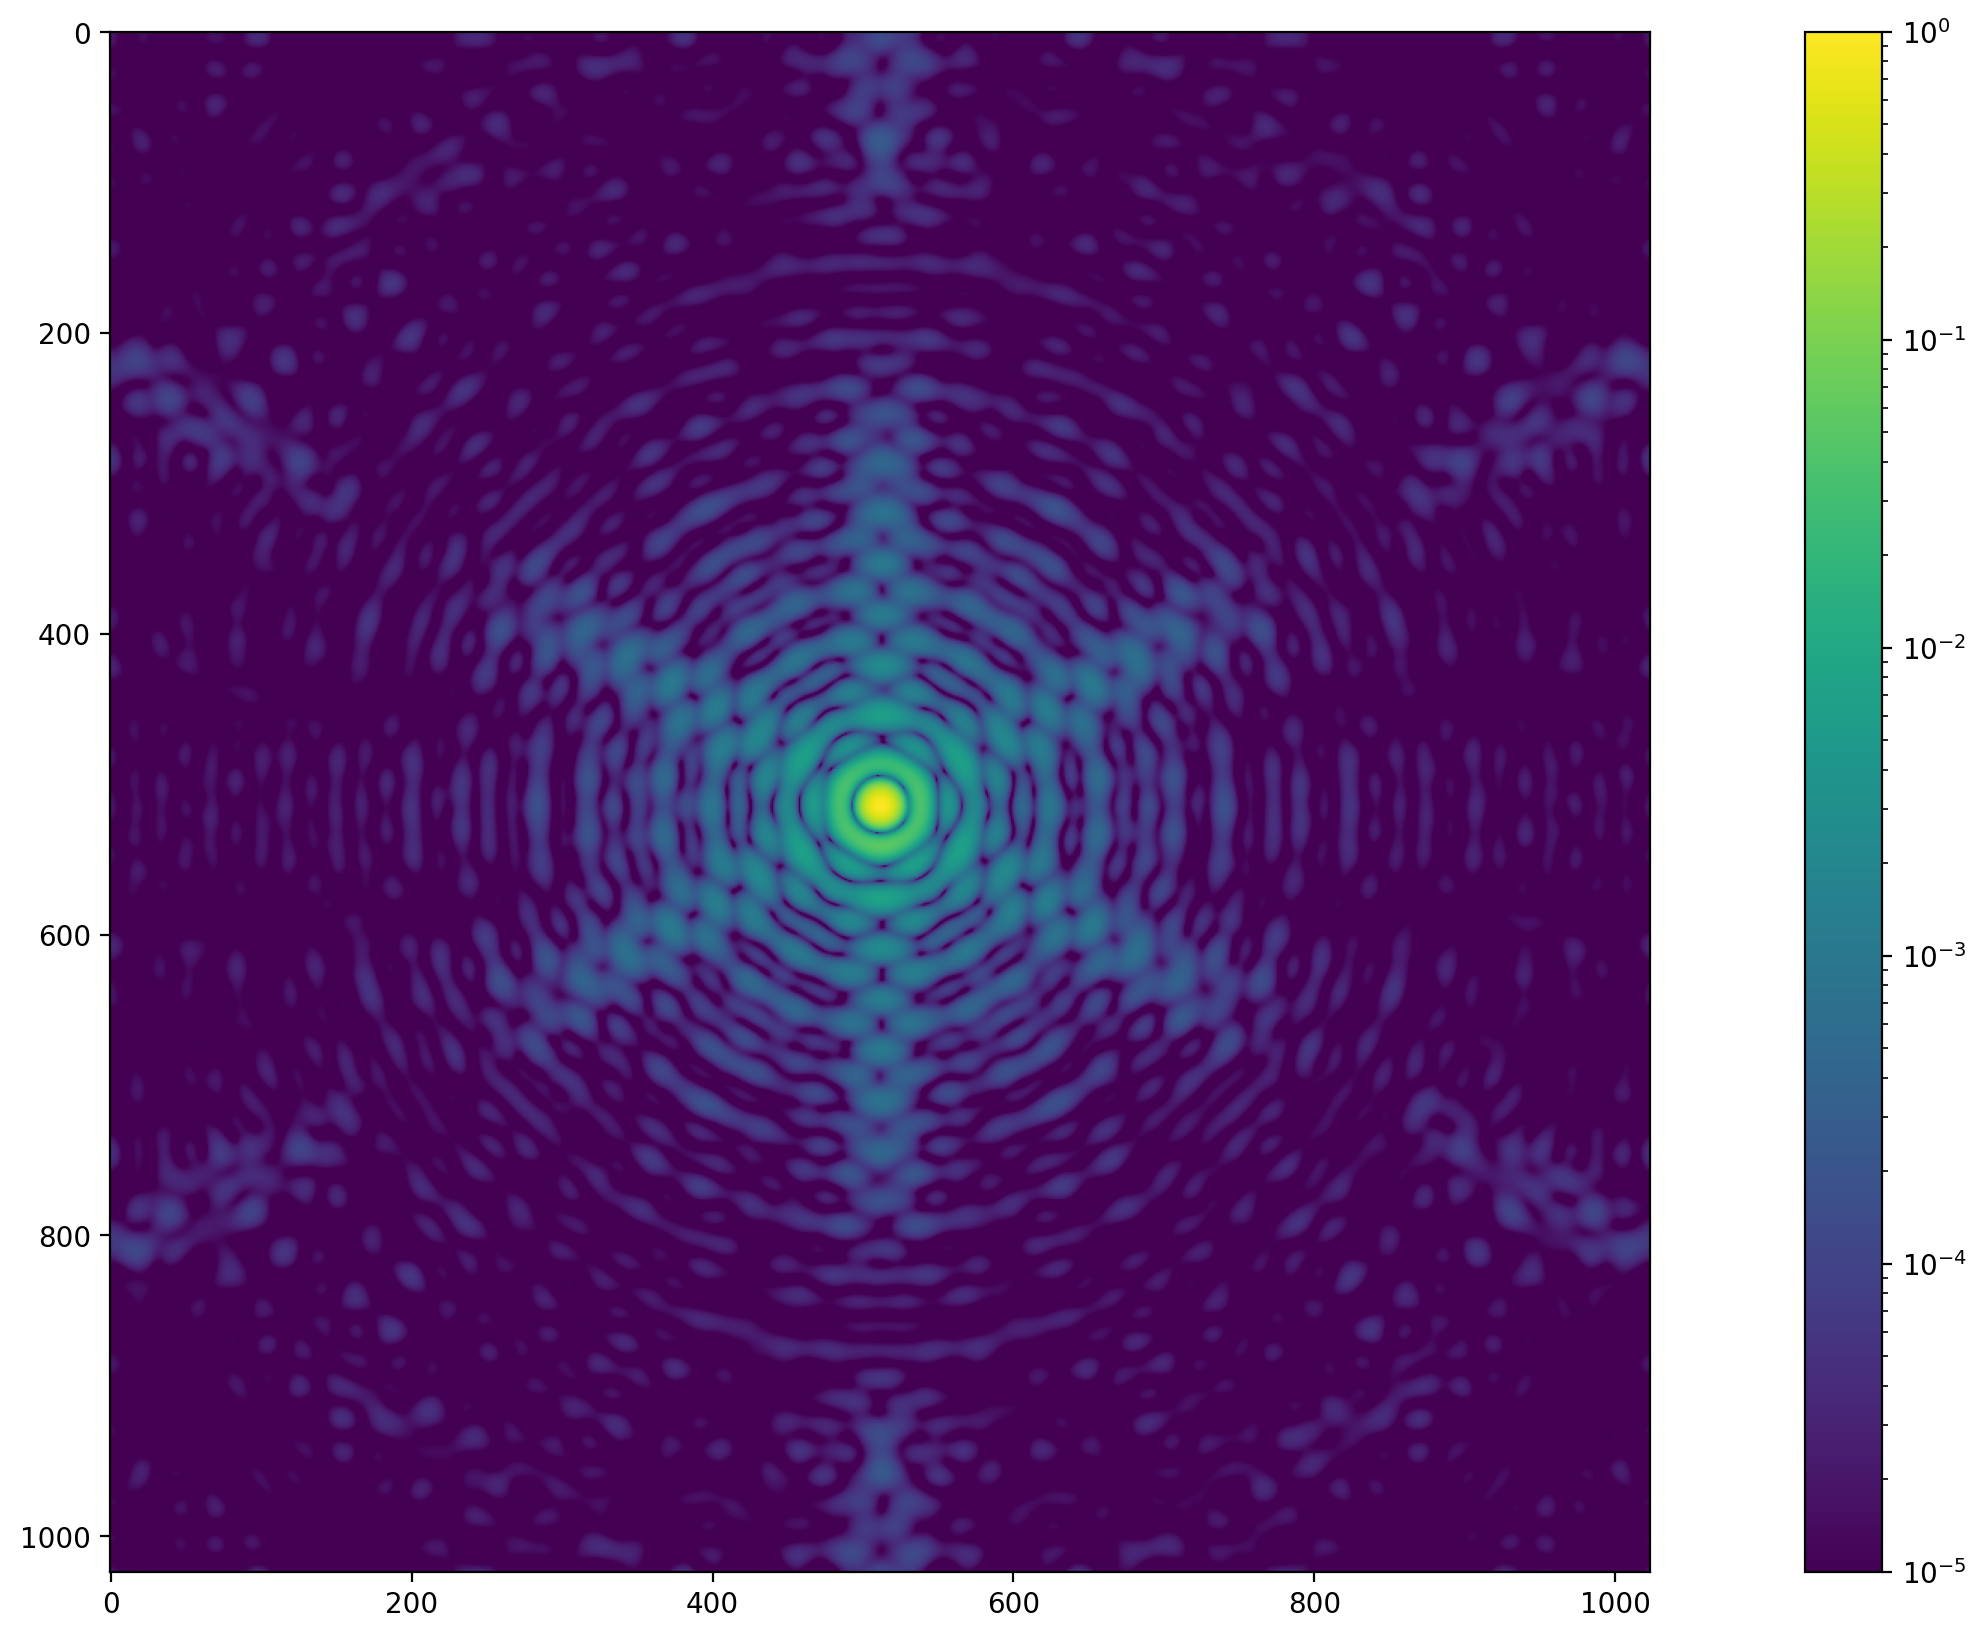

In [951]:
PSF, _ = infoTelescope.fftPSF(npx=64, pad=16)
plt.imshow(PSF,norm=mcolors.LogNorm(vmin=1e-5, vmax=1))
plt.colorbar()

In [881]:
import optiland
from optiland import optic, physical_apertures
from optiland import analysis
from optiland import wavefront
from optiland import mtf, psf

In [904]:
C = 1

In [905]:
#Pearl
lens = optic.Optic(name="Pearl")

# set aperture
lens.set_aperture(aperture_type="EPD", value=12.92*C)
aperture1 = physical_apertures.RadialAperture(r_min=1.38*C, r_max=6.42*C) 
a1 = physical_apertures.PolygonAperture(x=[1.380*C, 6.420*C, 6.420*C, 1.380*C], y=[.300*C, .300*C, -.300*C, -.300*C])
a2 = physical_apertures.PolygonAperture(x=[-3.469*C, -2.949*C, .260*C, -.260*C], y=[5.410*C, 5.710*C, .150*C, -.150*C])
a3 = physical_apertures.PolygonAperture(x=[-3.469*C, -2.949*C, .260*C, -.260*C], y=[-5.410*C, -5.710*C, -.150*C, .150*C])
a = aperture1 - a1 - a2 - a3

# set fields
lens.set_field_type(field_type="angle")
lens.add_field(y=0.17)

# set wavelengths
lens.add_wavelength(value=0.650, is_primary=True)

# add surfaces
lens.add_surface(index=0, radius=np.inf, thickness=np.inf)

lens.add_surface(
    index=1,
    radius=-16.256*C,
    thickness=-7.4*C,
    conic=-0.9953569,
    material="mirror",
    aperture=a,
    is_stop=True
)
lens.add_surface(
    index=2,
    radius=-1.660575*C,
    thickness=+7.45*C,
    conic=-1.566503,
    material="mirror",
    #aperture=aperture2
)
lens.add_surface(
    index=3,
    radius=-1.830517*C,
    thickness=-0.93363*C,
    conic=-0.718069,
    material="mirror",
    
)

lens.add_surface(
    index=4,
    radius=np.inf,
    thickness=1.22121*C,
    material="mirror",
    
)

lens.add_surface(index=5)

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

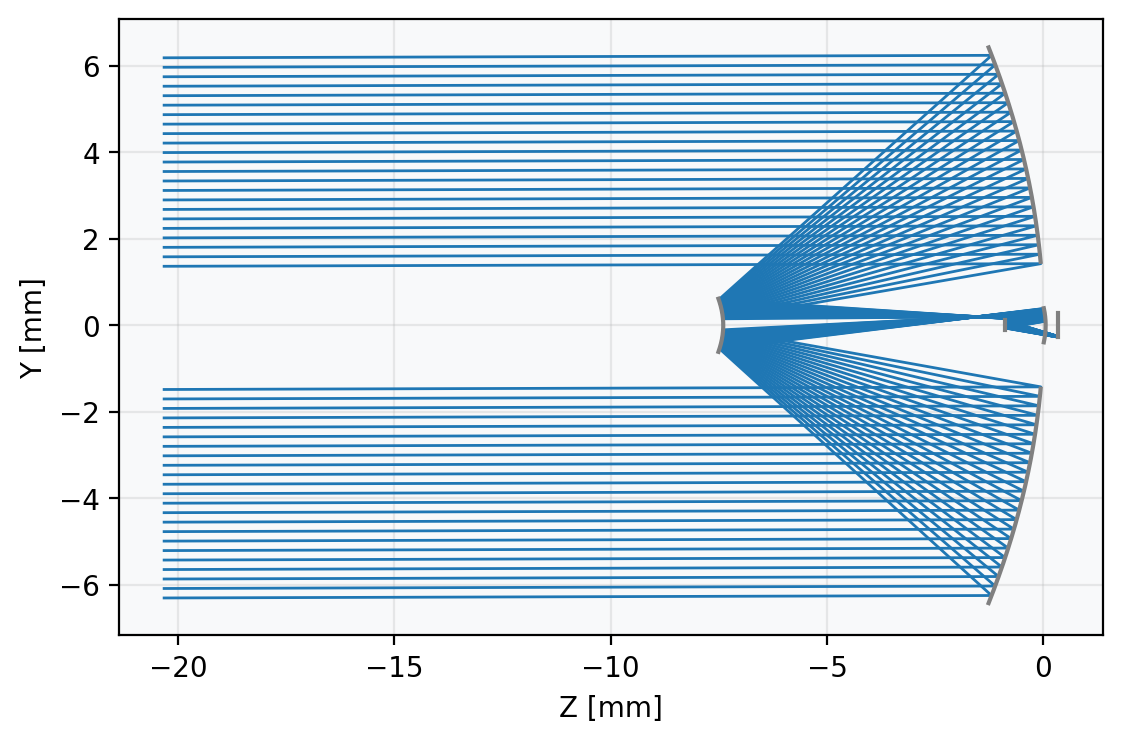

In [906]:
lens.draw(num_rays=60)

(<Figure size 700x550 with 2 Axes>,
 <Axes: title={'center': 'OPD Map: RMS=0.209 waves'}, xlabel='Pupil X', ylabel='Pupil Y'>)

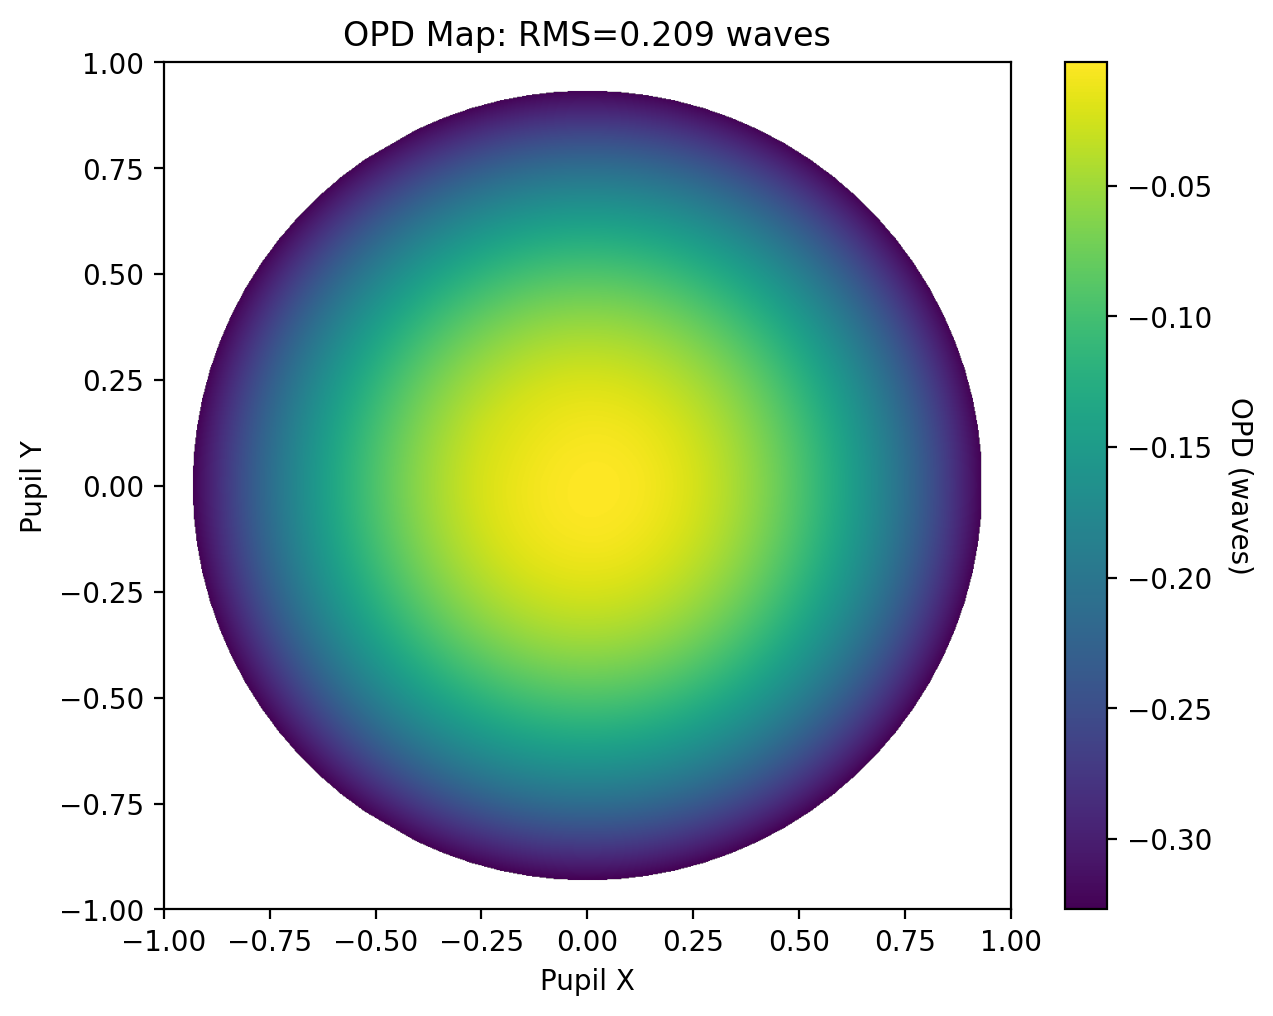

In [907]:
opd = wavefront.OPD(lens, field=(0, 0.17), wavelength=0.650)
opd.view(projection="2d", num_points=1024)

In [902]:
from optiland.psf import FFTPSF

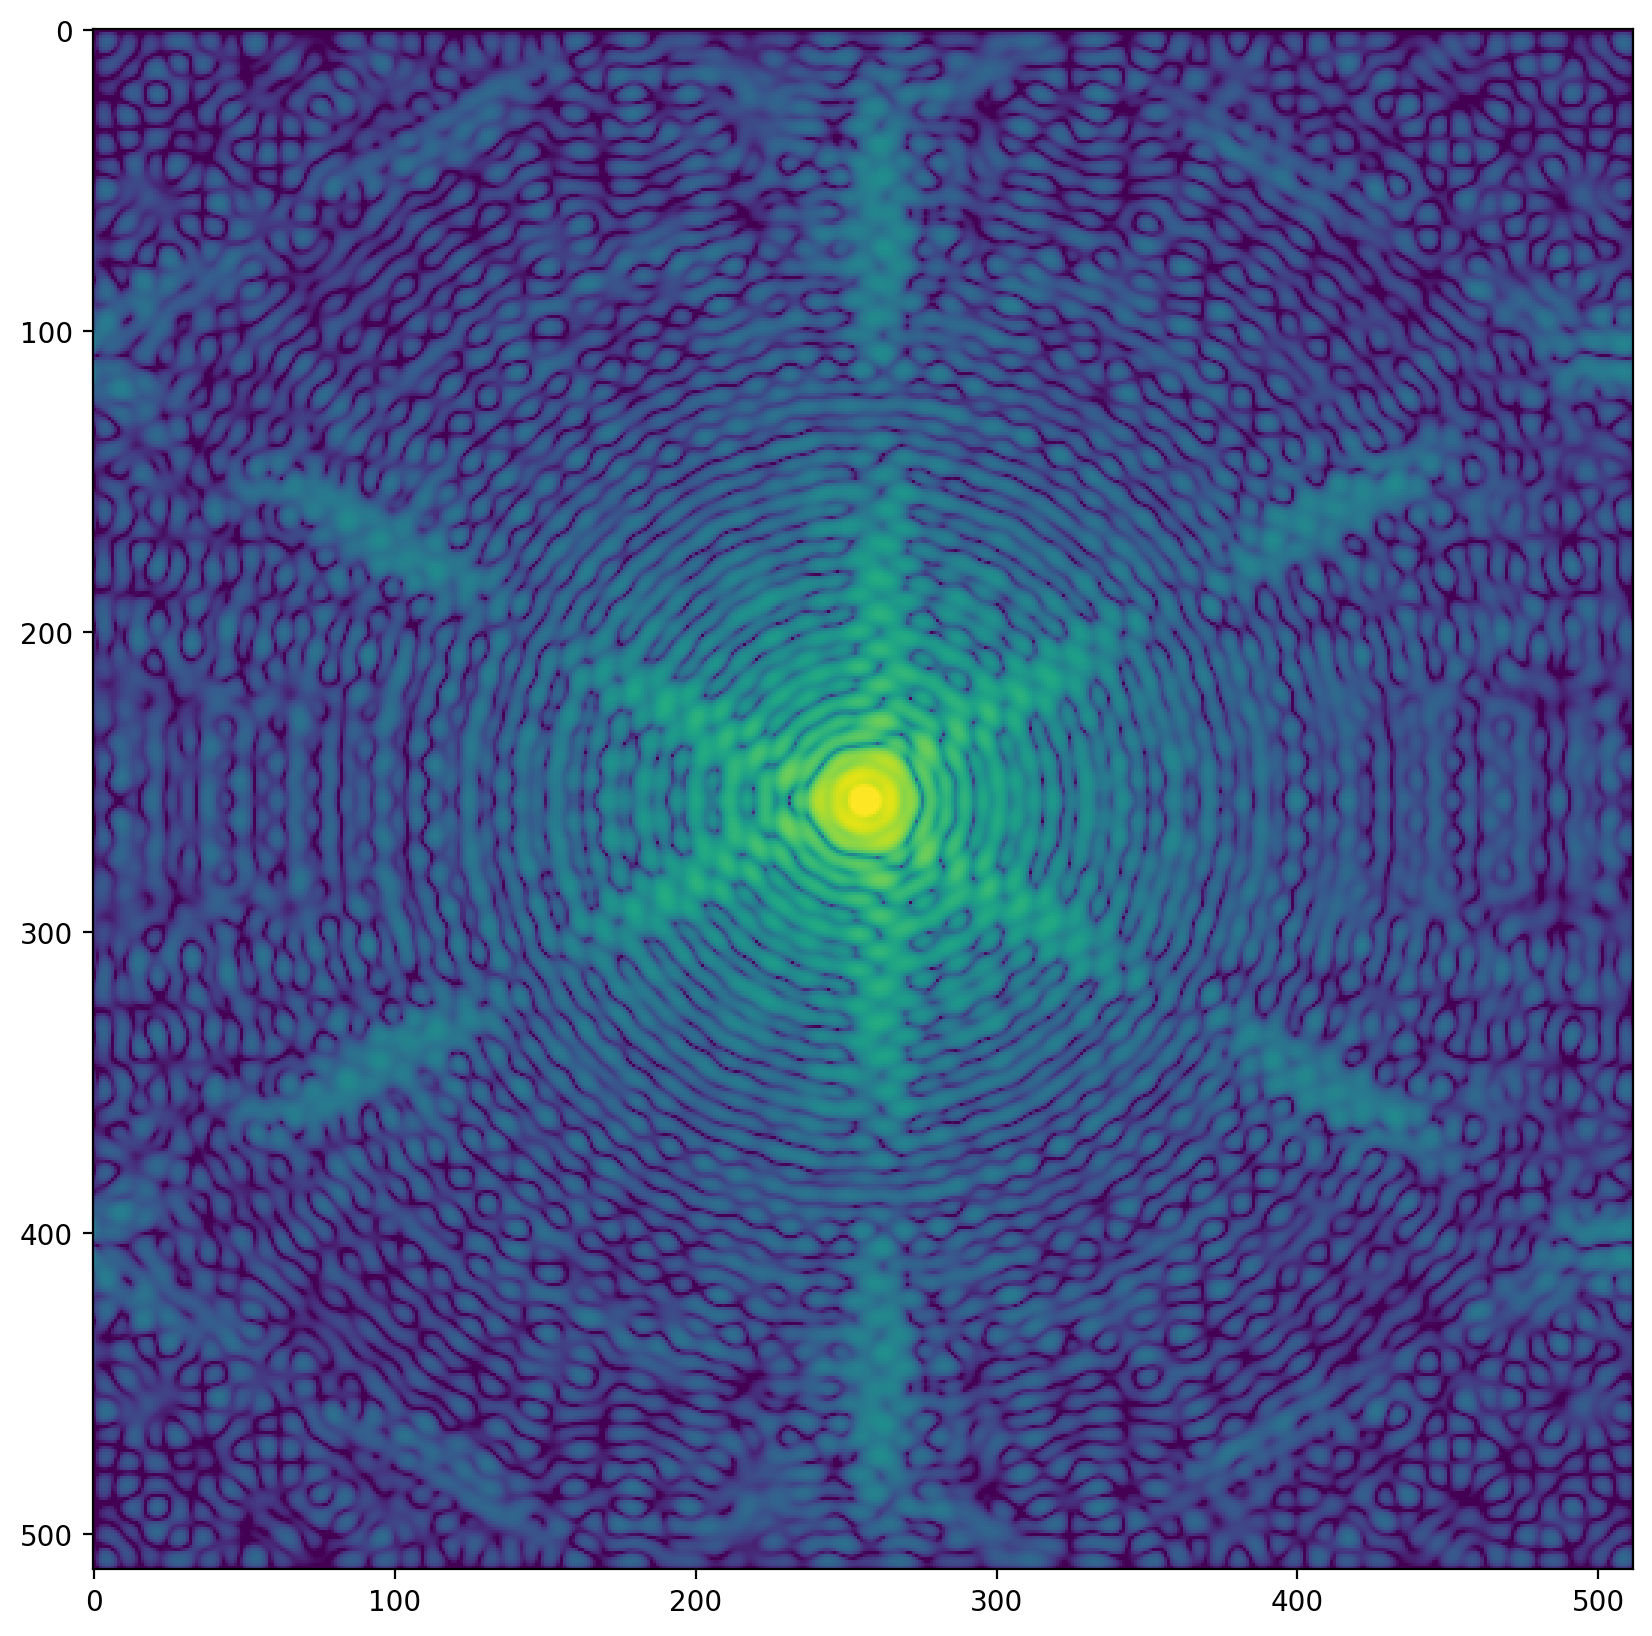

In [952]:
psf = FFTPSF(lens, field=(0, 0.0), wavelength=0.65, num_rays=256)
plt.imshow(psf.psf, norm=mcolors.LogNorm(vmin=1e-5, vmax=10))


In [9]:
def genpsf(WL=650e-9, pdx=0, pdy=0, pdz=0, ptx=0, pty=0, sdx=0, sdy=0, sdz=0, stx=0, sty=0, dterms=5):

    telescope = telescopeCreation(WL,pdx, pdy, pdz, ptx, pty, sdx, sdy, sdz, stx, sty)
    infoTelescope = details(telescope, fieldX=0, fieldY=0.17, wavelength=WL)
    PSF, _ = infoTelescope.fftPSF(npx=16, pad=2)
    r = decompose_psf(PSF, nterms=dterms, basis=basis_vectors)

    return r

vec_genpsf = np.frompyfunc(genpsf, 12, 1)

In [54]:
#Truth

pdx_true = 5
pdy_true = -7

## PSF 
ct = genpsf(WL=650e-9, pdx=pdx_true, pdy=pdy_true, dterms=3)


In [293]:
C = np.array([[ 1.16634361e-05, -2.32559604e-06, -1.38717321e-06],
               [-2.32559604e-06,  2.10292548e-06,  1.61782429e-07],
               [-1.38717321e-06,  1.61782429e-07,  1.31161567e-06]])
Cinv = np.linalg.inv(C)  # precision matrix
lnorm = -0.5 * (np.log(2 * np.pi) * 3 + np.log(np.linalg.det(C)))  # ln(normalization)

# log-likelihood
def loglike(theta):
    pdx,pdy = theta
    ## PSF
    c = genpsf(WL=650e-9, pdx=pdx, pdy=pdy, dterms=3)
    inv_sigma2 = 1.0 / (c**2)
    
    return -0.5 * np.dot(ct-c, np.dot(Cinv, ct-c)) + lnorm

# prior transform
def ptform(utheta):

    upx,upy = utheta

    mpx, spx = 0, 16  # mean and standard deviation
    lpx, hpx = -50, 50  # lower and upper bounds
    xpx = scipy.stats.truncnorm.ppf(upx, lpx, hpx, loc=mpx, scale=spx)

    mpy, spy = 0, 25  # mean and standard deviation
    lpy, hpy = -80, 80  # lower and upper bounds
    xpy = scipy.stats.truncnorm.ppf(upy, lpy, hpy, loc=mpy, scale=spy)

    return xpx,xpy

In [60]:
import dynesty.pool as dypool

In [466]:
import multiprocess, dill
dill.settings['recurse'] = True
dypool.mp = multiprocess

In [72]:
with dypool.Pool(8, loglike, ptform) as pool:

    dsampler = dynesty.DynamicNestedSampler(pool.loglike, pool.prior_transform, ndim=2, 
                                  sample='unif',pool=pool)
    dsampler.run_nested(maxiter=3000)
dres = dsampler.results

3501it [12:29,  4.67it/s, batch: 0 | bound: 4 | nc: 1 | ncall: 20180 | eff(%): 17.349 | loglstar:   -inf < 13.620 <    inf | logz: 11.236 +/-  0.048 | dlogz:  0.000 >  0.010] 


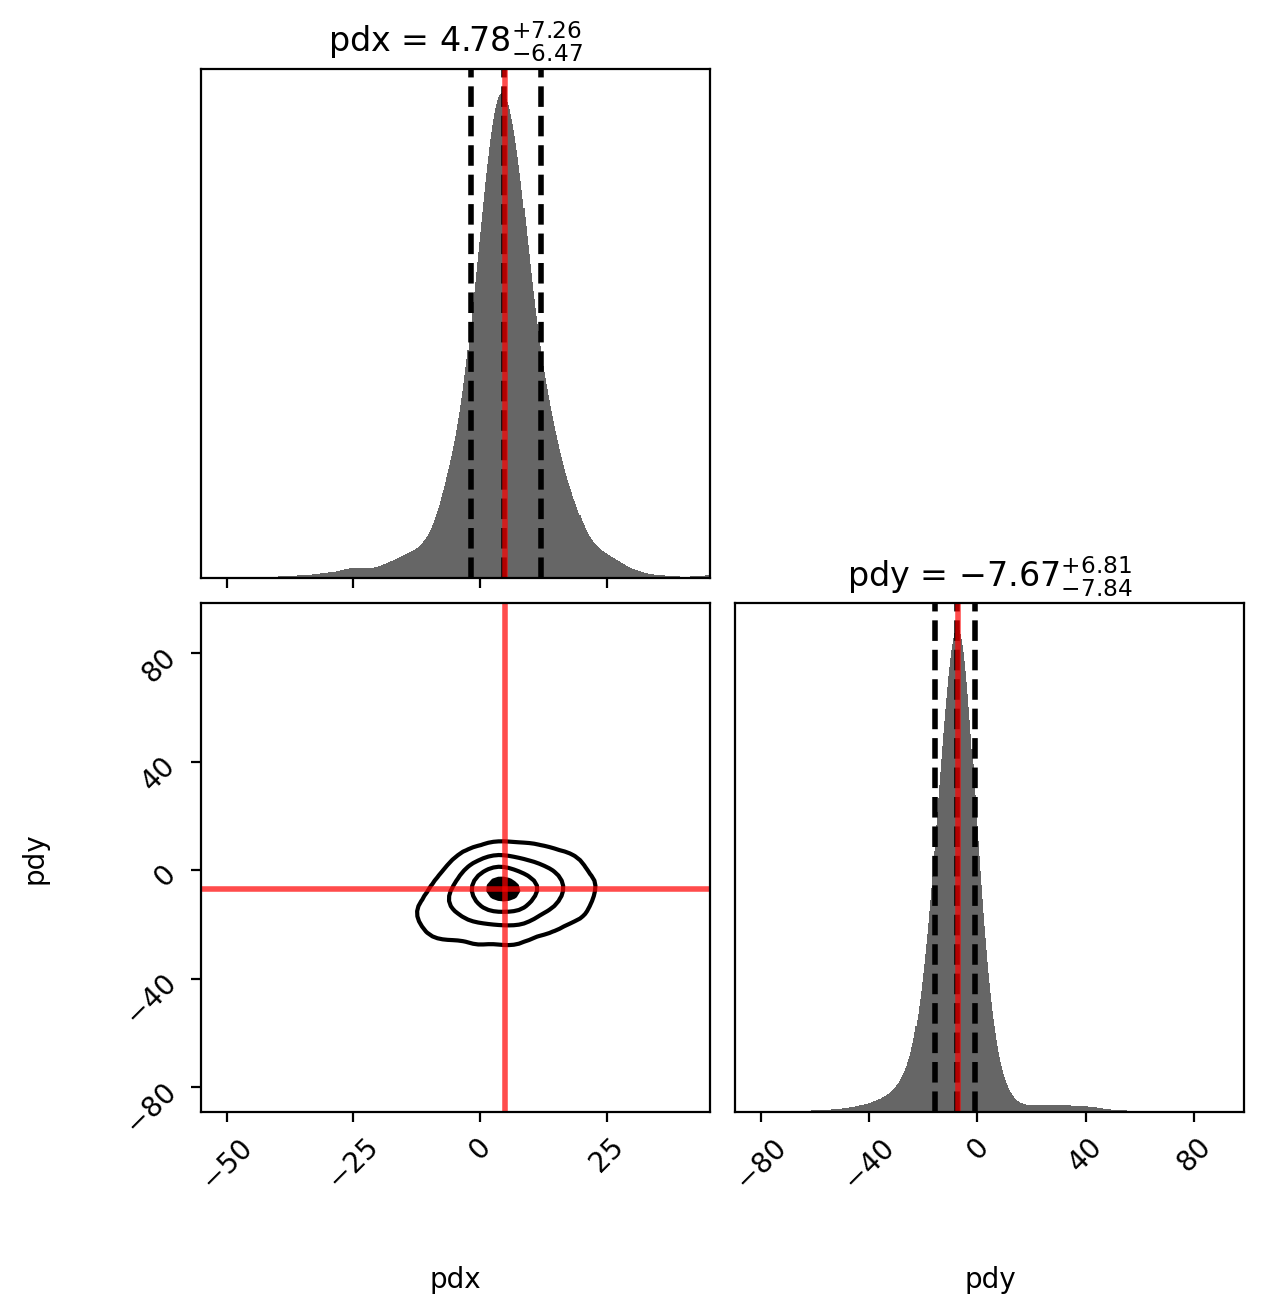

In [126]:
from dynesty import plotting as dyplot
plt.rcParams['text.usetex'] = False

labels = [r'pdx',r'pdy']
truths = [pdx_true,pdy_true]

fig, axes = dyplot.cornerplot(dres, truths=truths, show_titles=True, 
                               labels=labels, span = [1., 1.] , quantiles=(0.16, 0.5, 0.84), title_quantiles=(0.16, 0.5, 0.84),
                              fig=plt.subplots(2, 2, figsize=(7, 7)))

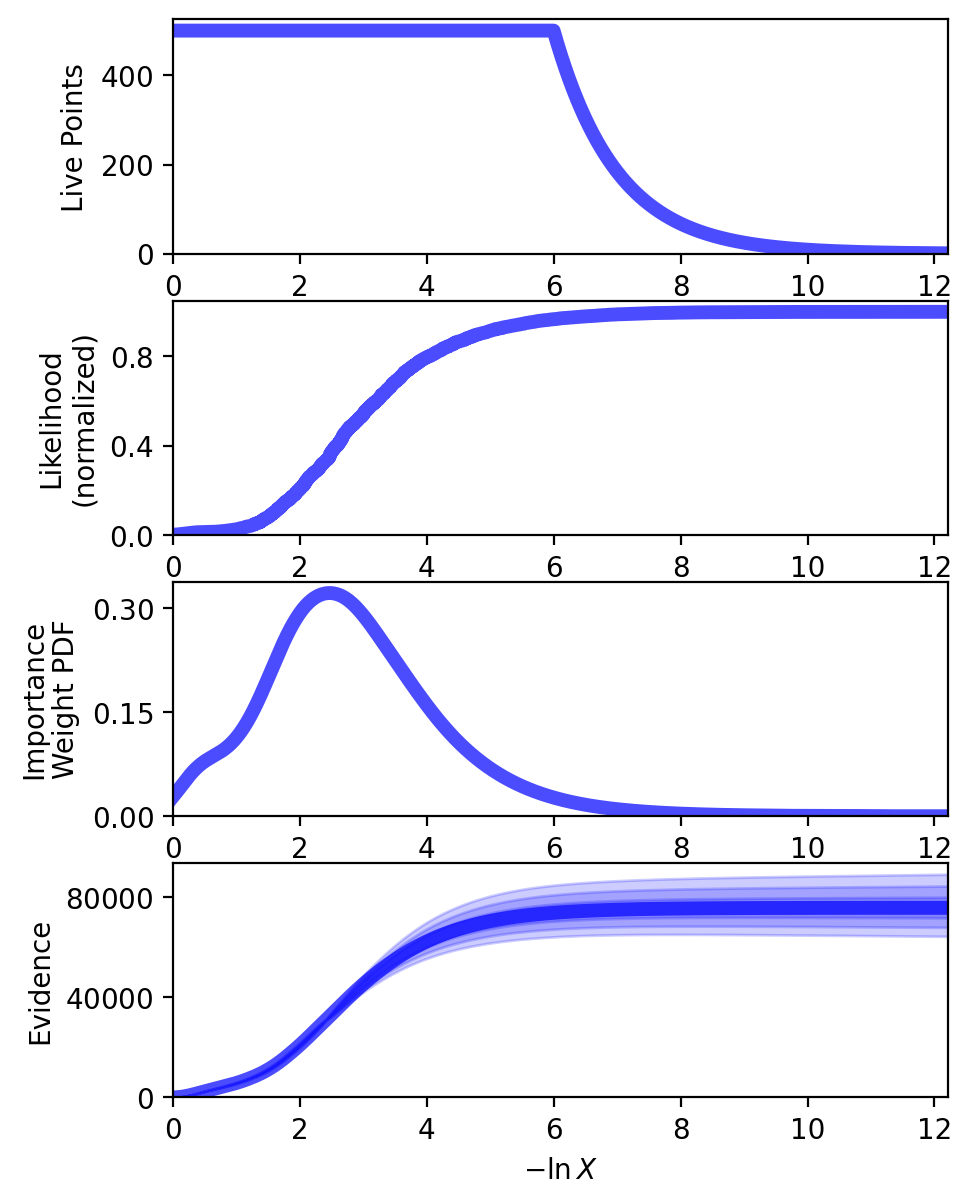

In [74]:
fig, axes = dyplot.runplot(dres, fig=plt.subplots(4, 1, figsize=(5, 7)))

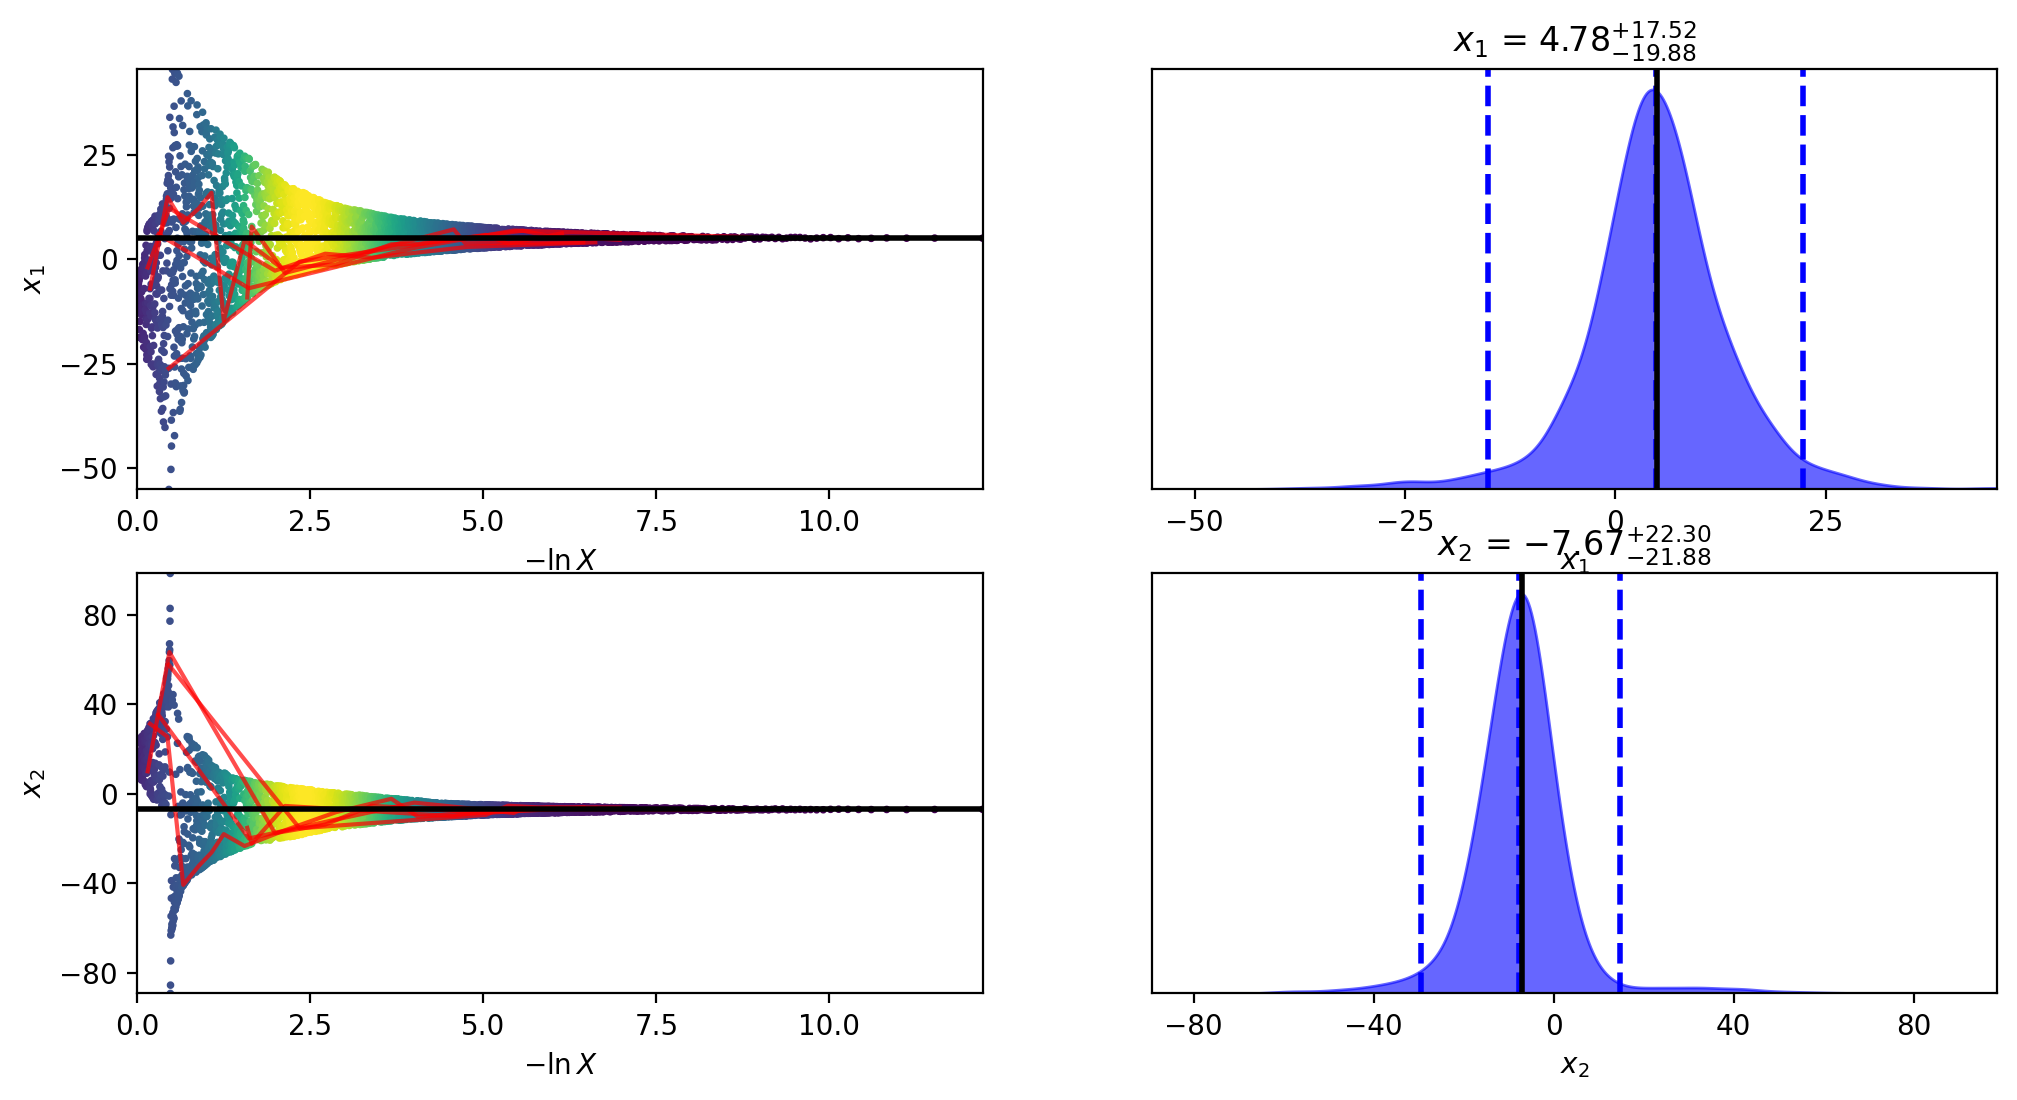

In [75]:
fig, axes = dyplot.traceplot(dres, truths=truths,
                             truth_color='black', show_titles=True,
                             trace_cmap='viridis', connect=True,
                             connect_highlight=range(5))

In [135]:
from scipy.optimize import minimize

In [264]:
def lstep(t):
    return np.sum((genpsf(WL=650e-9, pdx=t[0], pdy=t[1], dterms=3) - genpsf(WL=650e-9, pdx=t[2], pdy=t[3], dterms=3))**2)

In [643]:
C = np.array([[ 1.16634361e-05, -2.32559604e-06, -1.38717321e-06],
               [-2.32559604e-06,  2.10292548e-06,  1.61782429e-07],
               [-1.38717321e-06,  1.61782429e-07,  1.31161567e-06]])
Cinv = np.linalg.inv(C)  # precision matrix
lnorm = -0.5 * (np.log(2 * np.pi) * 3 + np.log(np.linalg.det(C)))  # ln(normalization)

def validator(xy, iter=30):
    x = xy[0]
    y = xy[1]
    ct = genpsf(650e-9, x, y, 0, 0, 0, 0, 0, 0, 0, 0, 3)
    
    # log-likelihood
    def loglike(theta):
        pdx,pdy = theta
        ## PSF
        c = genpsf(WL=650e-9, pdx=pdx, pdy=pdy, dterms=3)

        return -0.5 * np.dot(ct-c, np.dot(Cinv, ct-c)) + lnorm

    # prior transform
    def ptform(utheta):

        upx,upy = utheta

        mpx, spx = 0, 16  # mean and standard deviation
        lpx, hpx = -50, 50  # lower and upper bounds
        xpx = scipy.stats.truncnorm.ppf(upx, lpx, hpx, loc=mpx, scale=spx)

        mpy, spy = 0, 25  # mean and standard deviation
        lpy, hpy = -100, 100  # lower and upper bounds
        xpy = scipy.stats.truncnorm.ppf(upy, lpy, hpy, loc=mpy, scale=spy)

        return xpx,xpy
    
    dsampler = dynesty.DynamicNestedSampler(loglike, ptform, ndim=2, 
                                  sample='unif')
    dsampler.run_nested(maxiter=iter)
    dres = dsampler.results
    t0 = np.array([np.median(dres.samples[:,0]), np.median(dres.samples[:,1])])

    def lstep(t):
        return np.sum((ct - genpsf(WL=650e-9, pdx=t[0], pdy=t[1], dterms=3))**2)
    
    res = minimize(lstep, t0, method='Powell', tol = 1e-6, options={'disp': True})
    print(np.round(res.x, 3))
    return xy, t0, np.round(res.x, 3), np.sum(np.round(res.x, 3)-xy)**2

In [641]:
def valoop(xy):
    val300 = validator(xy, iter=300)
    val30 = validator(xy)
    if np.sum(val300 - val30) > 0:
        return validator(xy, iter=3000)
    else:
        return val30

In [652]:
%%prun
a,b,c,d = validator([-4.08, 8.09])

31it [00:39,  9.64it/s, batch: 0 | bound: 0 | nc: 1 | ncall: 32 | eff(%):  5.827 | loglstar:   -inf < -20.111 <    inf | logz: -24.157 +/-  0.083 | dlogz: 40.433 >  0.010]/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/dynesty/sampler.py:1082: UserWarning: The sampling was stopped short due to maxiter/maxcall limit the delta(log(z)) criterion is not achieved; posterior may be poorly sampled
  warnings.warn('The sampling was stopped short due to'
531it [00:39, 13.57it/s, batch: 0 | bound: 0 | nc: 1 | ncall: 532 | eff(%): 99.812 | loglstar:   -inf < 16.222 <    inf | logz: 11.801 +/-  0.090 | dlogz:  0.145 >  0.010]


Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 5
         Function evaluations: 248
[-4.08  8.09]
 

         3780962 function calls (3780157 primitive calls) in 56.277 seconds

   Ordered by: internal time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
    15620   16.688    0.001   16.688    0.001 {built-in method batoid._batoid.reflect}
    15620    5.298    0.000    5.298    0.000 {built-in method batoid._batoid.obscure}
     5467    3.833    0.001    3.833    0.001 {built-in method batoid._batoid.intersect}
      781    2.746    0.004   42.715    0.055 3190696417.py:198(wavefront)
    11503    2.490    0.000    2.490    0.000 {method 'copy' of 'numpy.ndarray' objects}
     1562    2.189    0.001   11.441    0.007 rayVector.py:219(asGrid)
   209917    1.979    0.000    1.980    0.000 {built-in method numpy.array}
    12779    1.865    0.000    1.868    0.000 numeric.py:401(full_like)
     3905    1.834    0.000    1.834    0.000 {built-in method batoid._batoid.sag}
     2343    1.574    0.001    1.669    0.001 core.py:1061(__call__)
    28317    1.532    0

In [649]:
d

np.float64(0.0)

In [631]:
validator([20.17,-26.28], iter=300) - validator([20.17,-26.28])

300it [00:58, 10.24it/s, batch: 0 | bound: 0 | nc: 1 | ncall: 431 | eff(%): 32.223 | loglstar:   -inf <  8.028 <    inf | logz:  4.220 +/-  0.073 | dlogz: 11.652 >  0.010]/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/dynesty/sampler.py:1082: UserWarning: The sampling was stopped short due to maxiter/maxcall limit the delta(log(z)) criterion is not achieved; posterior may be poorly sampled
  warnings.warn('The sampling was stopped short due to'
801it [00:58, 13.60it/s, batch: 0 | bound: 0 | nc: 1 | ncall: 932 | eff(%): 85.944 | loglstar:   -inf < 16.418 <    inf | logz: 14.970 +/-    nan | dlogz:  0.005 >  0.010]
/var/folders/w0/w0glfprn2b7c2dkswb2qrm040000gn/T/ipykernel_71103/1490154767.py:44: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(lstep, t0, method='L-BFGS-B', tol = 1e-6, options={'disp': True})


[ 0.755 -2.369]


31it [00:33, 11.53it/s, batch: 0 | bound: 0 | nc: 1 | ncall: 32 | eff(%):  5.827 | loglstar:   -inf < -9.587 <    inf | logz: -13.630 +/-  0.084 | dlogz: 30.098 >  0.010] /opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/dynesty/sampler.py:1082: UserWarning: The sampling was stopped short due to maxiter/maxcall limit the delta(log(z)) criterion is not achieved; posterior may be poorly sampled
  warnings.warn('The sampling was stopped short due to'
531it [00:33, 15.85it/s, batch: 0 | bound: 0 | nc: 1 | ncall: 532 | eff(%): 99.812 | loglstar:   -inf < 16.415 <    inf | logz: 14.920 +/-    nan | dlogz:  0.008 >  0.010]
/var/folders/w0/w0glfprn2b7c2dkswb2qrm040000gn/T/ipykernel_71103/1490154767.py:44: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(lstep, t0, method='L-BFGS-B', tol = 1e-6, options={'disp': True})


[-0.589 -1.736]


array([ 1.344, -0.633])

In [617]:
validator([-23.18, -60.3], iter=3000)

1917it [1:16:53,  2.61it/s, batch: 0 | bound: 2 | nc: 5 | ncall: 18603 | eff(%): 10.035 | loglstar:   -inf < 16.426 <    inf | logz: 15.120 +/-  0.046 | dlogz:  0.077 >  0.010]  /opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/dynesty/bounding.py:707: UserWarning: The enlargement factor for the ellipsoidal bounds determined from bootstrapping is very large. If you are using uniform sampling that may mean that the sampling will be inefficient. This may be caused by a very complex posterior shape. You may consider using more livepoints or different sampler (i.e. rslice or rwalk) or alternatively disable bootstrap (bootstrap=0)
  warnings.warn(
1973it [1:18:37,  1.07s/it, batch: 0 | bound: 5 | nc: 13 | ncall: 20162 | eff(%):  9.549 | loglstar:   -inf < 16.426 <    inf | logz: 15.129 +/-  0.045 | dlogz:  0.069 >  0.010] /opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/dynesty/bounding.py:707: UserWarning: The enlargement factor for the ellipsoidal bounds determi

Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 104
         Function evaluations: 194
[-23.18 -60.3 ]


In [310]:
xy = np.zeros((50,2))
for i in range(50):
    x = np.random.normal(loc=0,scale=10)
    y = np.random.normal(loc=0,scale=20)
    ars = np.array([np.round(x,2),np.round(y,2)])
    xy[i] = ars

In [321]:
np.sum(np.round(res.x, 3)-xy[0])**2

np.float64(84.0889)

In [347]:
validator([-2.2, -40.65])

31it [00:32, 12.19it/s, batch: 0 | bound: 0 | nc: 1 | ncall: 31 | eff(%):  5.838 | loglstar:   -inf < -13.740 <    inf | logz: -18.444 +/-  0.088 | dlogz: 35.026 >  0.010]/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/dynesty/sampler.py:1082: UserWarning: The sampling was stopped short due to maxiter/maxcall limit the delta(log(z)) criterion is not achieved; posterior may be poorly sampled
  warnings.warn('The sampling was stopped short due to'
531it [00:32, 16.34it/s, batch: 0 | bound: 0 | nc: 1 | ncall: 531 | eff(%): 100.000 | loglstar:   -inf < 16.426 <    inf | logz: 15.112 +/-    nan | dlogz:  0.007 >  0.010]


Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 42
         Function evaluations: 134
[ 80.964 100.   ]


In [327]:
x, y = -2.2, -40.65
ct = genpsf(650e-9, x, y, 0, 0, 0, 0, 0, 0, 0, 0, 3)
    
# log-likelihood
def loglike(theta):
    pdx,pdy = theta
    ## PSF
    c = genpsf(WL=650e-9, pdx=pdx, pdy=pdy, dterms=3)
    return -0.5 * np.dot(ct-c, np.dot(Cinv, ct-c)) + lnorm
# prior transform
def ptform(utheta):
    upx,upy = utheta
    mpx, spx = 0, 16  # mean and standard deviation
    lpx, hpx = -50, 50  # lower and upper bounds
    xpx = scipy.stats.truncnorm.ppf(upx, lpx, hpx, loc=mpx, scale=spx)
    mpy, spy = 0, 25  # mean and standard deviation
    lpy, hpy = -100, 100  # lower and upper bounds
    xpy = scipy.stats.truncnorm.ppf(upy, lpy, hpy, loc=mpy, scale=spy)
    return xpx,xpy

dsampler = dynesty.DynamicNestedSampler(loglike, ptform, ndim=2, 
                              sample='unif')
dsampler.run_nested(maxiter=30)
dres = dsampler.results
t0 = np.array([np.median(dres.samples[:,0]), np.median(dres.samples[:,1])])

def lstep(t):
    return np.sum((genpsf(WL=650e-9, pdx=x, pdy=y, dterms=3) - genpsf(WL=650e-9, pdx=t[0], pdy=t[1], dterms=3))**2)

res = minimize(lstep, t0, method='Nelder-Mead', tol = 1e-6, options={'disp': True})
print(x,y,np.round(res.x, 3))

31it [00:33, 10.69it/s, batch: 0 | bound: 0 | nc: 1 | ncall: 33 | eff(%):  5.816 | loglstar:   -inf < -11.500 <    inf | logz: -15.905 +/-  0.087 | dlogz: 32.436 >  0.010]/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/dynesty/sampler.py:1082: UserWarning: The sampling was stopped short due to maxiter/maxcall limit the delta(log(z)) criterion is not achieved; posterior may be poorly sampled
  warnings.warn('The sampling was stopped short due to'
531it [00:33, 16.02it/s, batch: 0 | bound: 0 | nc: 1 | ncall: 533 | eff(%): 99.625 | loglstar:   -inf < 16.426 <    inf | logz: 15.142 +/-    nan | dlogz:  0.007 >  0.010]


Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 42
         Function evaluations: 136
-2.2 -40.65 [ 12.953 145.621]


In [339]:
dsampler.add_batch(maxiter=550)

2184it [02:06,  3.55it/s, batch: 4 | bound: 0 | nc: 3 | ncall: 4783 | eff(%): 33.016 | loglstar: 15.882 < 16.046 < 16.134 | logz: 15.144 +/-  0.083 | stop:    nan] /opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/dynesty/sampler.py:1082: UserWarning: The sampling was stopped short due to maxiter/maxcall limit the delta(log(z)) criterion is not achieved; posterior may be poorly sampled
  warnings.warn('The sampling was stopped short due to'
2684it [02:06, 21.18it/s, batch: 4 | bound: 0 | nc: 1 | ncall: 5283 | eff(%): 40.574 | loglstar: 15.882 < 16.426 < 16.134 | logz: 15.144 +/-  0.083 | stop:    nan]


(np.int64(5283),
 2684,
 (np.float64(15.881581349757846), np.float64(16.13431885805539)),
 IteratorResult(worst=np.int64(138), ustar=array([0.48290564, 0.05010856]), vstar=array([ -0.68579704, -41.09504805]), loglstar=np.float64(16.426084764674595), logvol=nan, logwt=nan, logz=np.float64(15.143859155016521), logzvar=np.float64(0.006881022502991906), h=nan, nc=1, worst_it=np.int64(2167), boundidx=np.int64(0), bounditer=0, eff=np.float64(40.57445200302343), delta_logz=nan, blob=None, proposal_stats=None))

In [ ]:
[-23.18 -60.3 ], [0.40571714,1.80070682], [  6.372 145.416], 55351.031824

In [609]:
#dres = dsampler.results
t0 = np.array([0.40571714,1.80070682])

def lstep(t):
    return np.sum((genpsf(WL=650e-9, pdx=-23.18, pdy=-60.03, dterms=3) - genpsf(WL=650e-9, pdx=t[0], pdy=t[1], dterms=3))**2)

res = minimize(lstep, t0, method='Powell', tol = 1e-10, options={'disp': True})
print(np.round(res.x, 3))

Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 2
         Function evaluations: 61
[236.111   1.801]


In [342]:
np.median(dres.samples[:,0]), np.median(dres.samples[:,1])

(np.float64(-0.1833771734249024), np.float64(-6.864253426429731))

In [341]:
dres

             niter: 2684
             ncall: array([1, 1, 1, ..., 1, 1, 1], shape=(2684,))
               eff: np.float64(40.57445200302343)
           samples: array([[ -7.76346168,  -4.22768544],
       [ -5.12958496,  -4.14276562],
       [ -8.41094572,  -4.30237009],
       ...,
       [  2.22245654, -40.48487006],
       [ -1.19946768, -41.05083385],
       [ -2.05673253, -40.90452427]], shape=(2684, 2))
        samples_id: array([ 434,  141,  439, ..., 1857, 1772, 1533], shape=(2684,))
     samples_batch: array([0, 0, 0, ..., 3, 3, 3], shape=(2684,))
        samples_it: array([   0,    0,    0, ..., 1583, 1583, 1612], shape=(2684,))
         samples_u: array([[0.31376144, 0.43285608],
       [0.37425712, 0.43419234],
       [0.29955385, 0.4316815 ],
       ...,
       [0.55523681, 0.05268117],
       [0.47012059, 0.05029155],
       [0.44885853, 0.05090086]], shape=(2684, 2))
         samples_n: array([500, 500, 500, ...,   3,   2,   1], shape=(2684,))
             logwt: array([

In [563]:
import pandas as pd

data = pd.read_csv('validate.txt', header = None)

In [565]:
x = np.zeros(319)
y = np.zeros(319)

for i in range(319):
    f = data[0][i].split()
    if f[0] == '[':
        x[i] = float(f[1].replace('[', ''))
        y[i] = float(f[2].replace(']', ''))
    else:
        x[i] = float(f[0].replace('[', ''))
        y[i] = float(f[1].replace(']', ''))
    

In [566]:
f = data[3]
f = np.array(f)

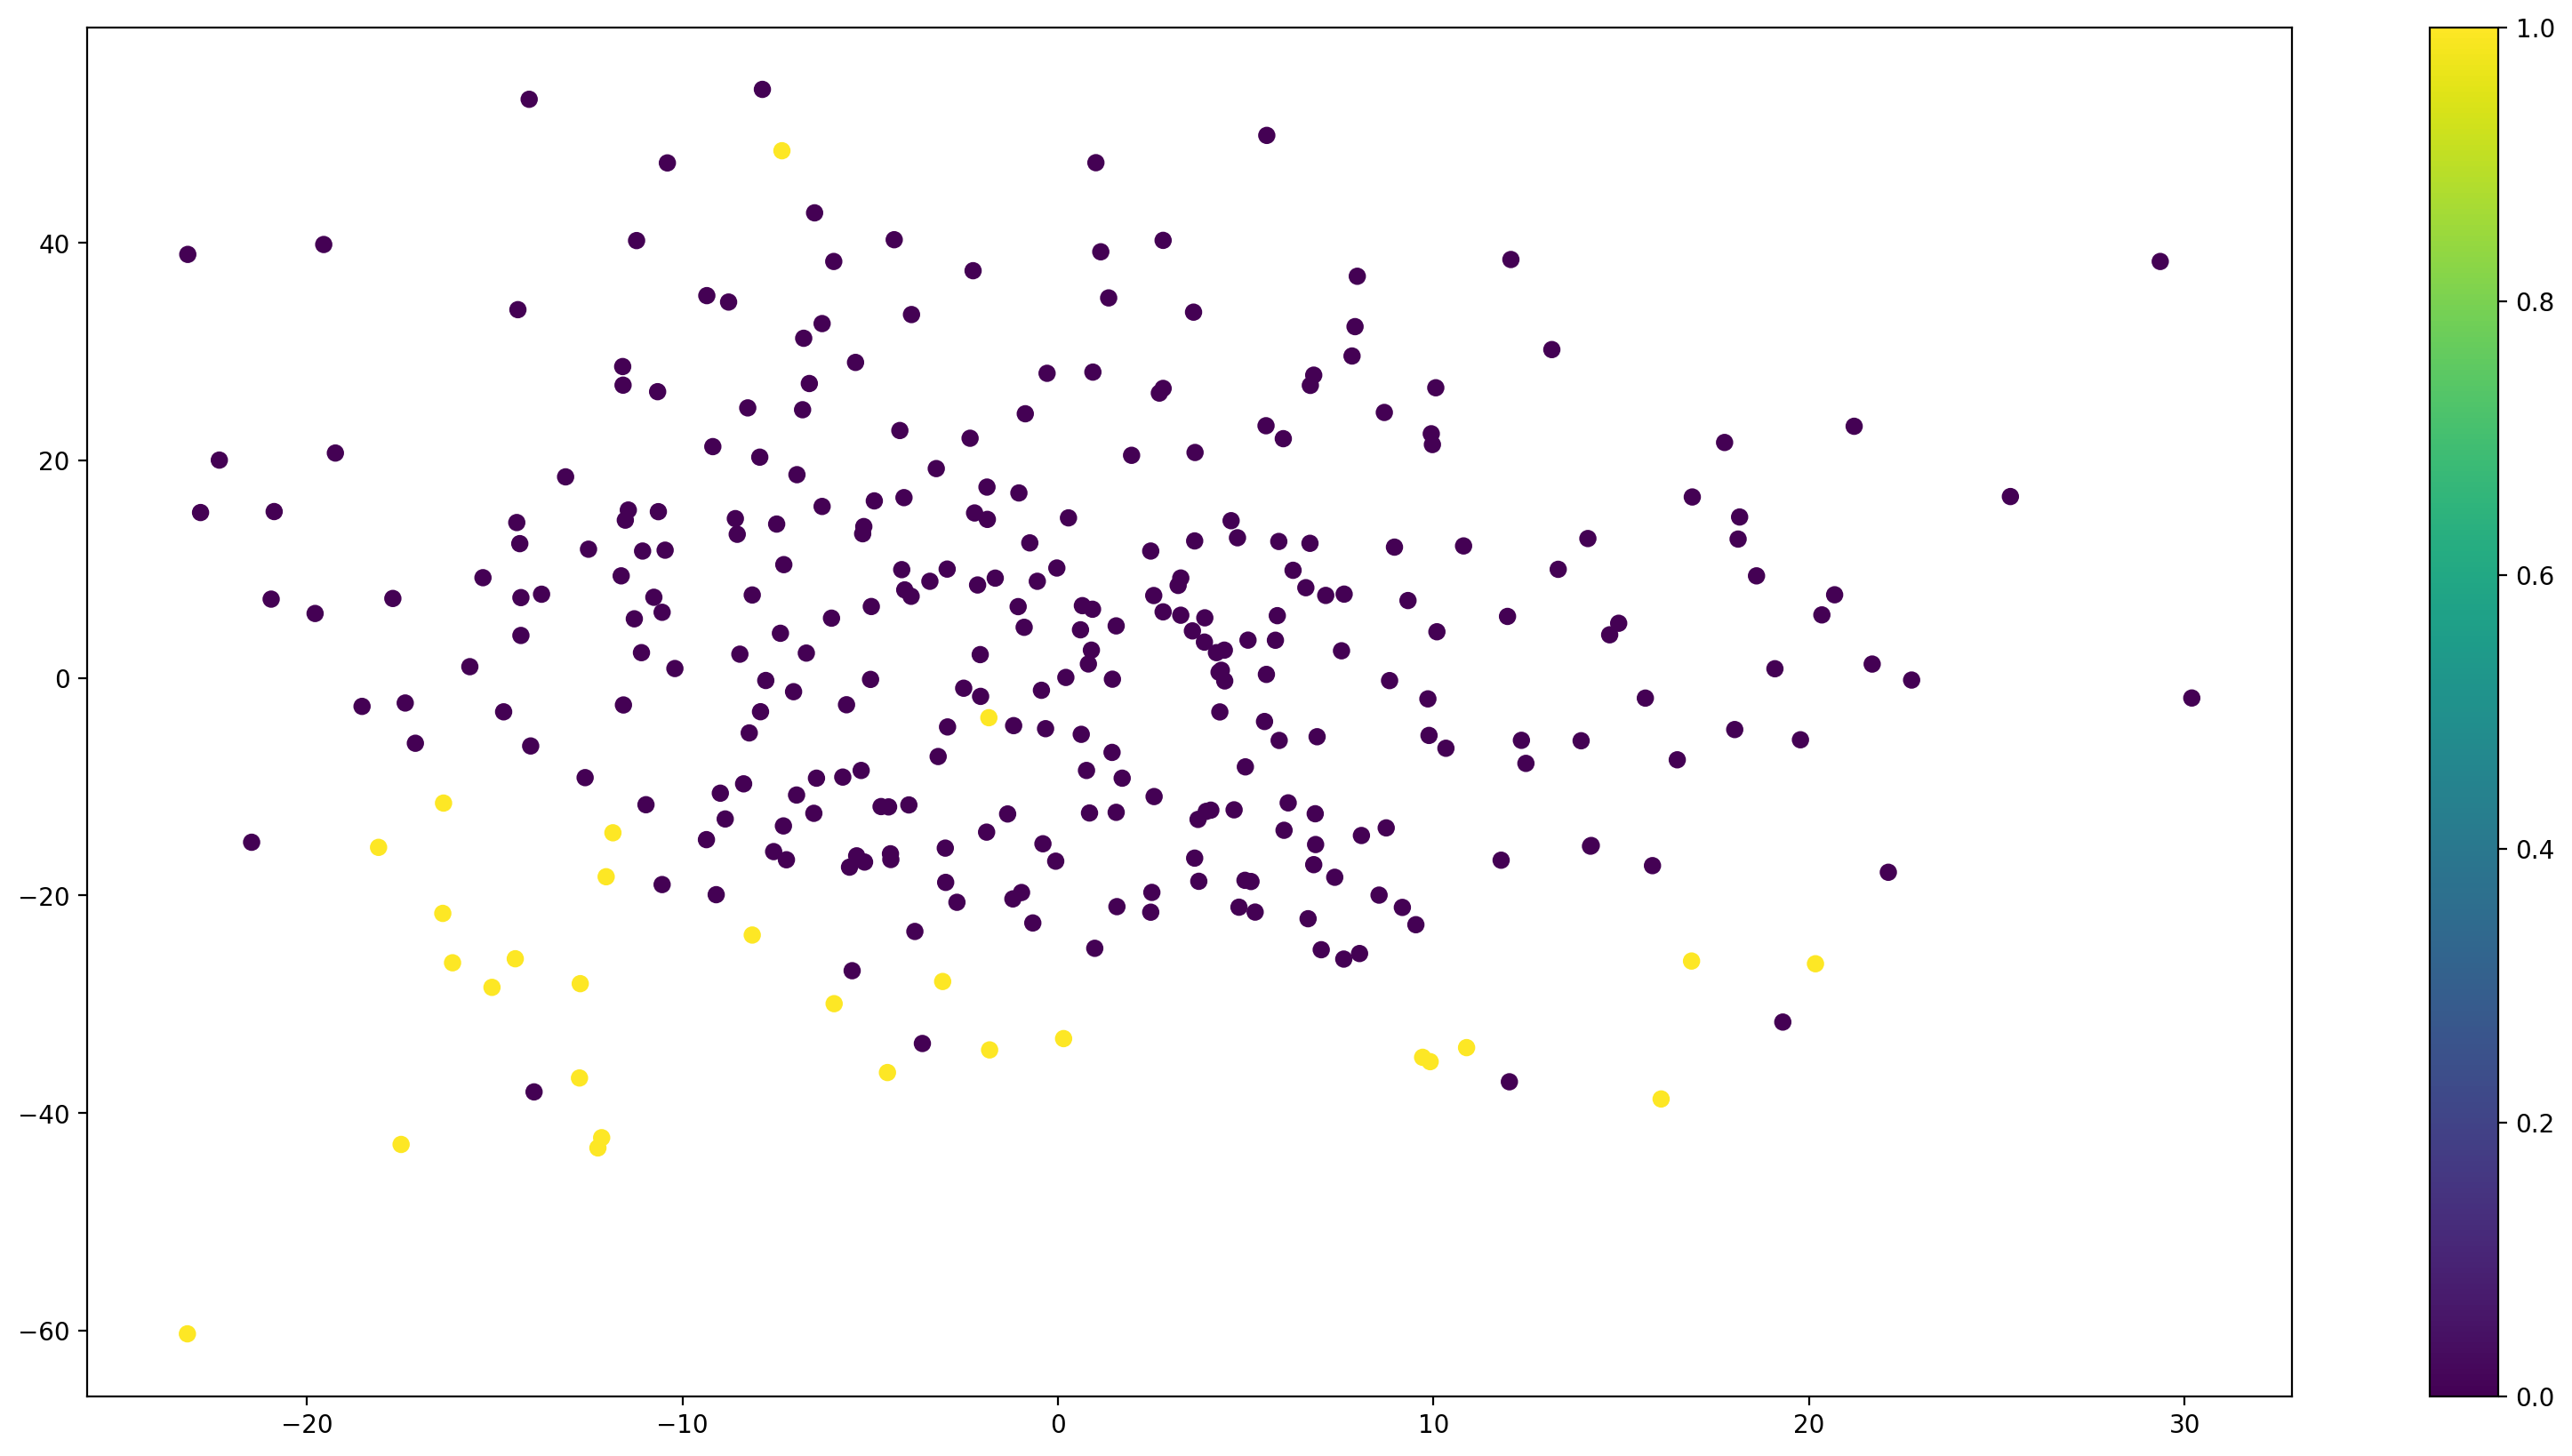

In [567]:
plt.scatter(x,y,c=f, vmin=0, vmax=1)
plt.colorbar()

In [458]:
((len(f)-len(f[f>0]))/len(f))*100

90.66666666666666

In [459]:
#Truth

pdx_true = 0
pdy_true = 0
pdz_true = 0
ptx_true = 0
pty_true = 0

## PSF 
ct = genpsf(WL=650e-9, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, ptx=ptx_true, pty=pty_true, dterms=10)


In [ ]:
C = np.array([[ 1.95217098e-06, -3.52965214e-07, -3.60790734e-07,
        -9.43891161e-07, -3.57022231e-08,  3.89075106e-08,
        -1.11990453e-07, -9.75792830e-08,  1.49161292e-08,
         2.90431373e-08],
       [-3.52965214e-07,  2.59310817e-07,  7.02828928e-08,
         1.73921702e-07,  2.36115456e-08,  1.04447448e-08,
         2.50266535e-08,  8.67798804e-08, -5.82527269e-10,
        -1.08442723e-08],
       [-3.60790734e-07,  7.02828928e-08,  2.35737397e-07,
         1.81548812e-07,  2.45522355e-08, -2.15336090e-08,
         7.61072353e-08,  2.24218746e-08, -1.34345537e-09,
        -1.31383970e-09],
       [-9.43891161e-07,  1.73921702e-07,  1.81548812e-07,
         5.41282117e-07,  1.92925978e-08, -1.88621534e-08,
         7.04819267e-08,  5.61234022e-08, -8.27513978e-09,
        -9.63681833e-09],
       [-3.57022231e-08,  2.36115456e-08,  2.45522355e-08,
         1.92925978e-08,  1.01061902e-08, -9.90773130e-10,
         8.46982080e-09,  8.04694459e-09,  6.11423248e-10,
         4.22532357e-10],
       [ 3.89075106e-08,  1.04447448e-08, -2.15336090e-08,
        -1.88621534e-08, -9.90773130e-10,  1.13298321e-08,
        -7.34131471e-09,  5.96676719e-09,  9.71753340e-10,
        -7.64019688e-09],
       [-1.11990453e-07,  2.50266535e-08,  7.61072353e-08,
         7.04819267e-08,  8.46982080e-09, -7.34131471e-09,
         3.39924229e-08,  1.04194043e-08,  1.63701474e-10,
         1.34616764e-09],
       [-9.75792830e-08,  8.67798804e-08,  2.24218746e-08,
         5.61234022e-08,  8.04694459e-09,  5.96676719e-09,
         1.04194043e-08,  4.08087774e-08,  2.73275819e-10,
        -1.23673623e-08],
       [ 1.49161292e-08, -5.82527269e-10, -1.34345537e-09,
        -8.27513978e-09,  6.11423248e-10,  9.71753340e-10,
         1.63701474e-10,  2.73275819e-10,  6.21806158e-10,
        -3.75025981e-10],
       [ 2.90431373e-08, -1.08442723e-08, -1.31383970e-09,
        -9.63681833e-09,  4.22532357e-10, -7.64019688e-09,
         1.34616764e-09, -1.23673623e-08, -3.75025981e-10,
         3.83042240e-08]])
Cinv = np.linalg.inv(C)  # precision matrix
lnorm = -0.5 * (np.log(2 * np.pi) * 5 + np.log(np.linalg.det(C)))  # ln(normalization)

# log-likelihood
def loglike(theta):
    pdx,pdy,pdz,ptx,pty = theta
    ## PSF
    c = genpsf(WL=650e-9, pdx=pdx, pdy=pdy, pdz=pdz, ptx=ptx, pty=pty, dterms=10)
    
    return -0.5 * np.dot(ct-c, np.dot(Cinv, ct-c)) + lnorm

# prior transform
def ptform(utheta):

    upx,upy,upz,utpx,utpy = utheta

    mpx, spx = 0, 16  # mean and standard deviation
    lpx, hpx = -50, 50  # lower and upper bounds
    xpx = scipy.stats.truncnorm.ppf(upx, lpx, hpx, loc=mpx, scale=spx)

    mpy, spy = 0, 25  # mean and standard deviation
    lpy, hpy = -80, 80  # lower and upper bounds
    xpy = scipy.stats.truncnorm.ppf(upy, lpy, hpy, loc=mpy, scale=spy)

    mpz, spz = 0, 5  # mean and standard deviation
    lpz, hpz = -15, 15  # lower and upper bounds
    xpz = scipy.stats.truncnorm.ppf(upz, lpz, hpz, loc=mpz, scale=spz)

    mtpx, stpx = 0, 2  # mean and standard deviation
    ltpx, htpx = -8, 8  # lower and upper bounds
    tpx = scipy.stats.truncnorm.ppf(utpx, ltpx, htpx, loc=mtpx, scale=stpx)

    mtpy, stpy = 0, 1  # mean and standard deviation
    ltpy, htpy = -4, 4  # lower and upper bounds
    tpy = scipy.stats.truncnorm.ppf(utpy, ltpy, htpy, loc=mtpy, scale=stpy)

    return xpx,xpy,xpz,tpx,tpy

In [528]:
import os
os.environ['OMP_NUM_THREADS'] = '4'

In [533]:
with dypool.Pool(8, loglike, ptform) as pool:

    dsampler = dynesty.DynamicNestedSampler(pool.loglike, pool.prior_transform, ndim=5, 
                                  sample='unif',pool=pool)
    dsampler.run_nested(maxiter=10000)
dres = dsampler.results

9495it [12:02:53,  1.02it/s, batch: 2 | bound: 4 | nc: 23 | ncall: 1081935 | eff(%):  0.867 | loglstar: 79.858 < 80.208 < 80.313 | logz: 72.278 +/-  0.113 | stop:  2.544]              /opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/dynesty/sampler.py:1082: UserWarning: The sampling was stopped short due to maxiter/maxcall limit the delta(log(z)) criterion is not achieved; posterior may be poorly sampled
  warnings.warn('The sampling was stopped short due to'
10001it [12:02:53,  4.34s/it, batch: 2 | bound: 4 | nc: 1 | ncall: 1082573 | eff(%):  0.913 | loglstar: 79.858 < 82.759 < 80.313 | logz: 72.278 +/-  0.113 | stop:    nan]


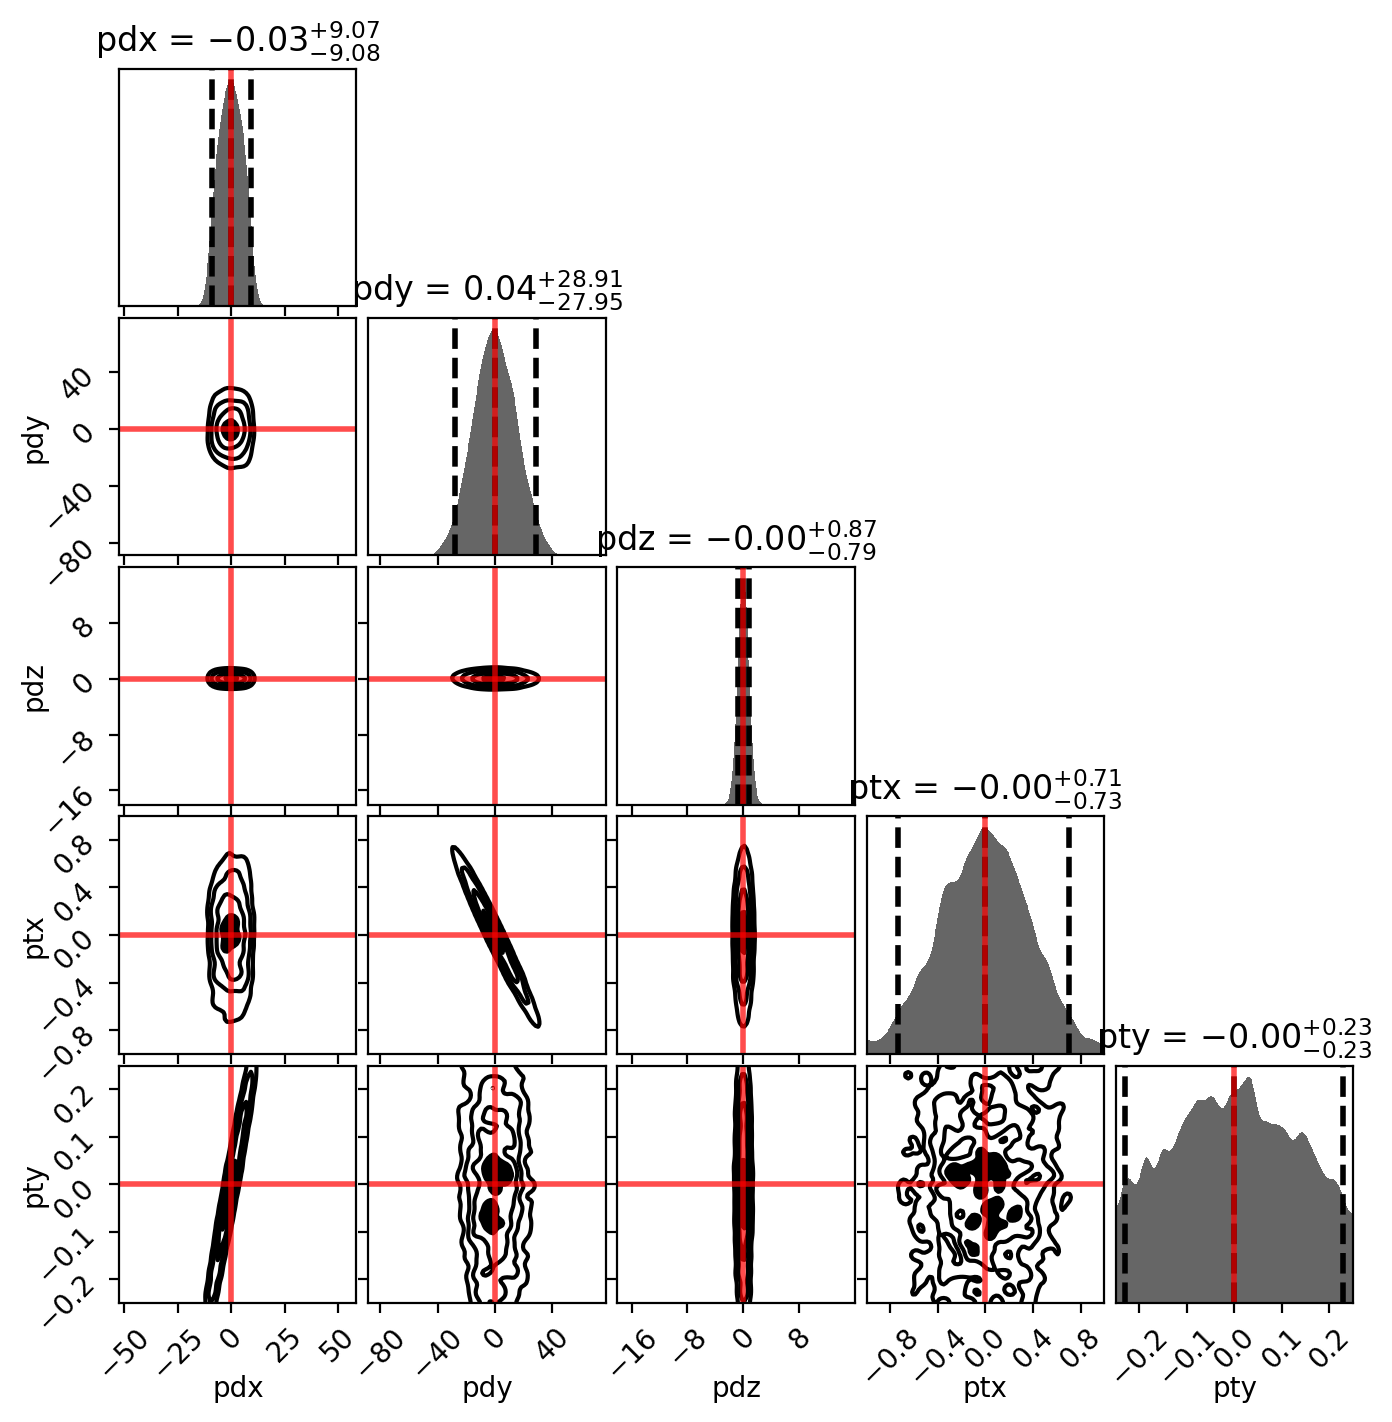

In [534]:
from dynesty import plotting as dyplot
plt.rcParams['text.usetex'] = False

labels = [r'pdx',r'pdy',r'pdz',r'ptx',r'pty']
truths = [pdx_true,pdy_true,pdz_true,ptx_true,pty_true]

fig, axes = dyplot.cornerplot(dres, truths=truths, show_titles=True, 
                               labels=labels, span = [1., 1., 1., 1., 1.],
                              fig=plt.subplots(5, 5, figsize=(7, 7)))

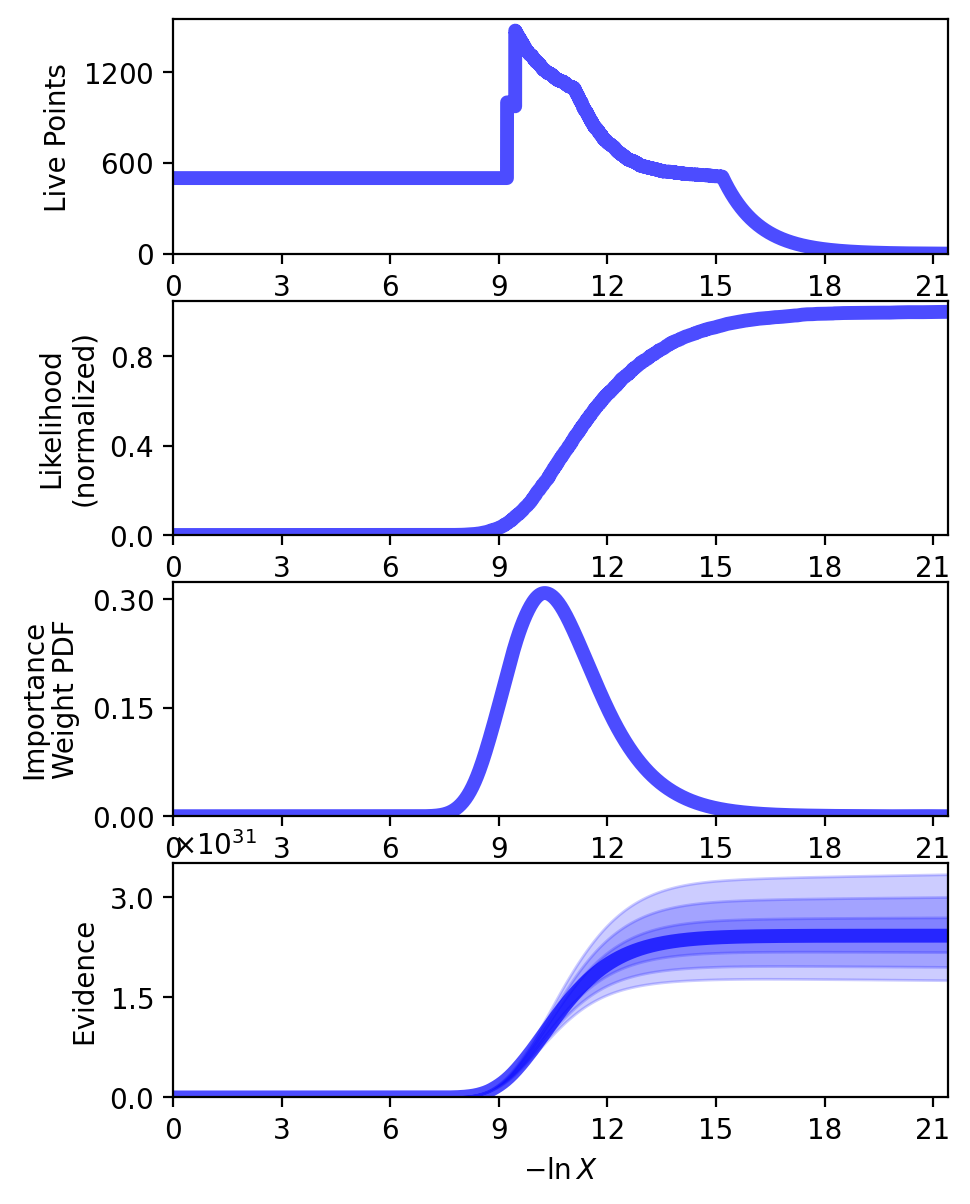

In [535]:
fig, axes = dyplot.runplot(dres, fig=plt.subplots(4, 1, figsize=(5, 7)))

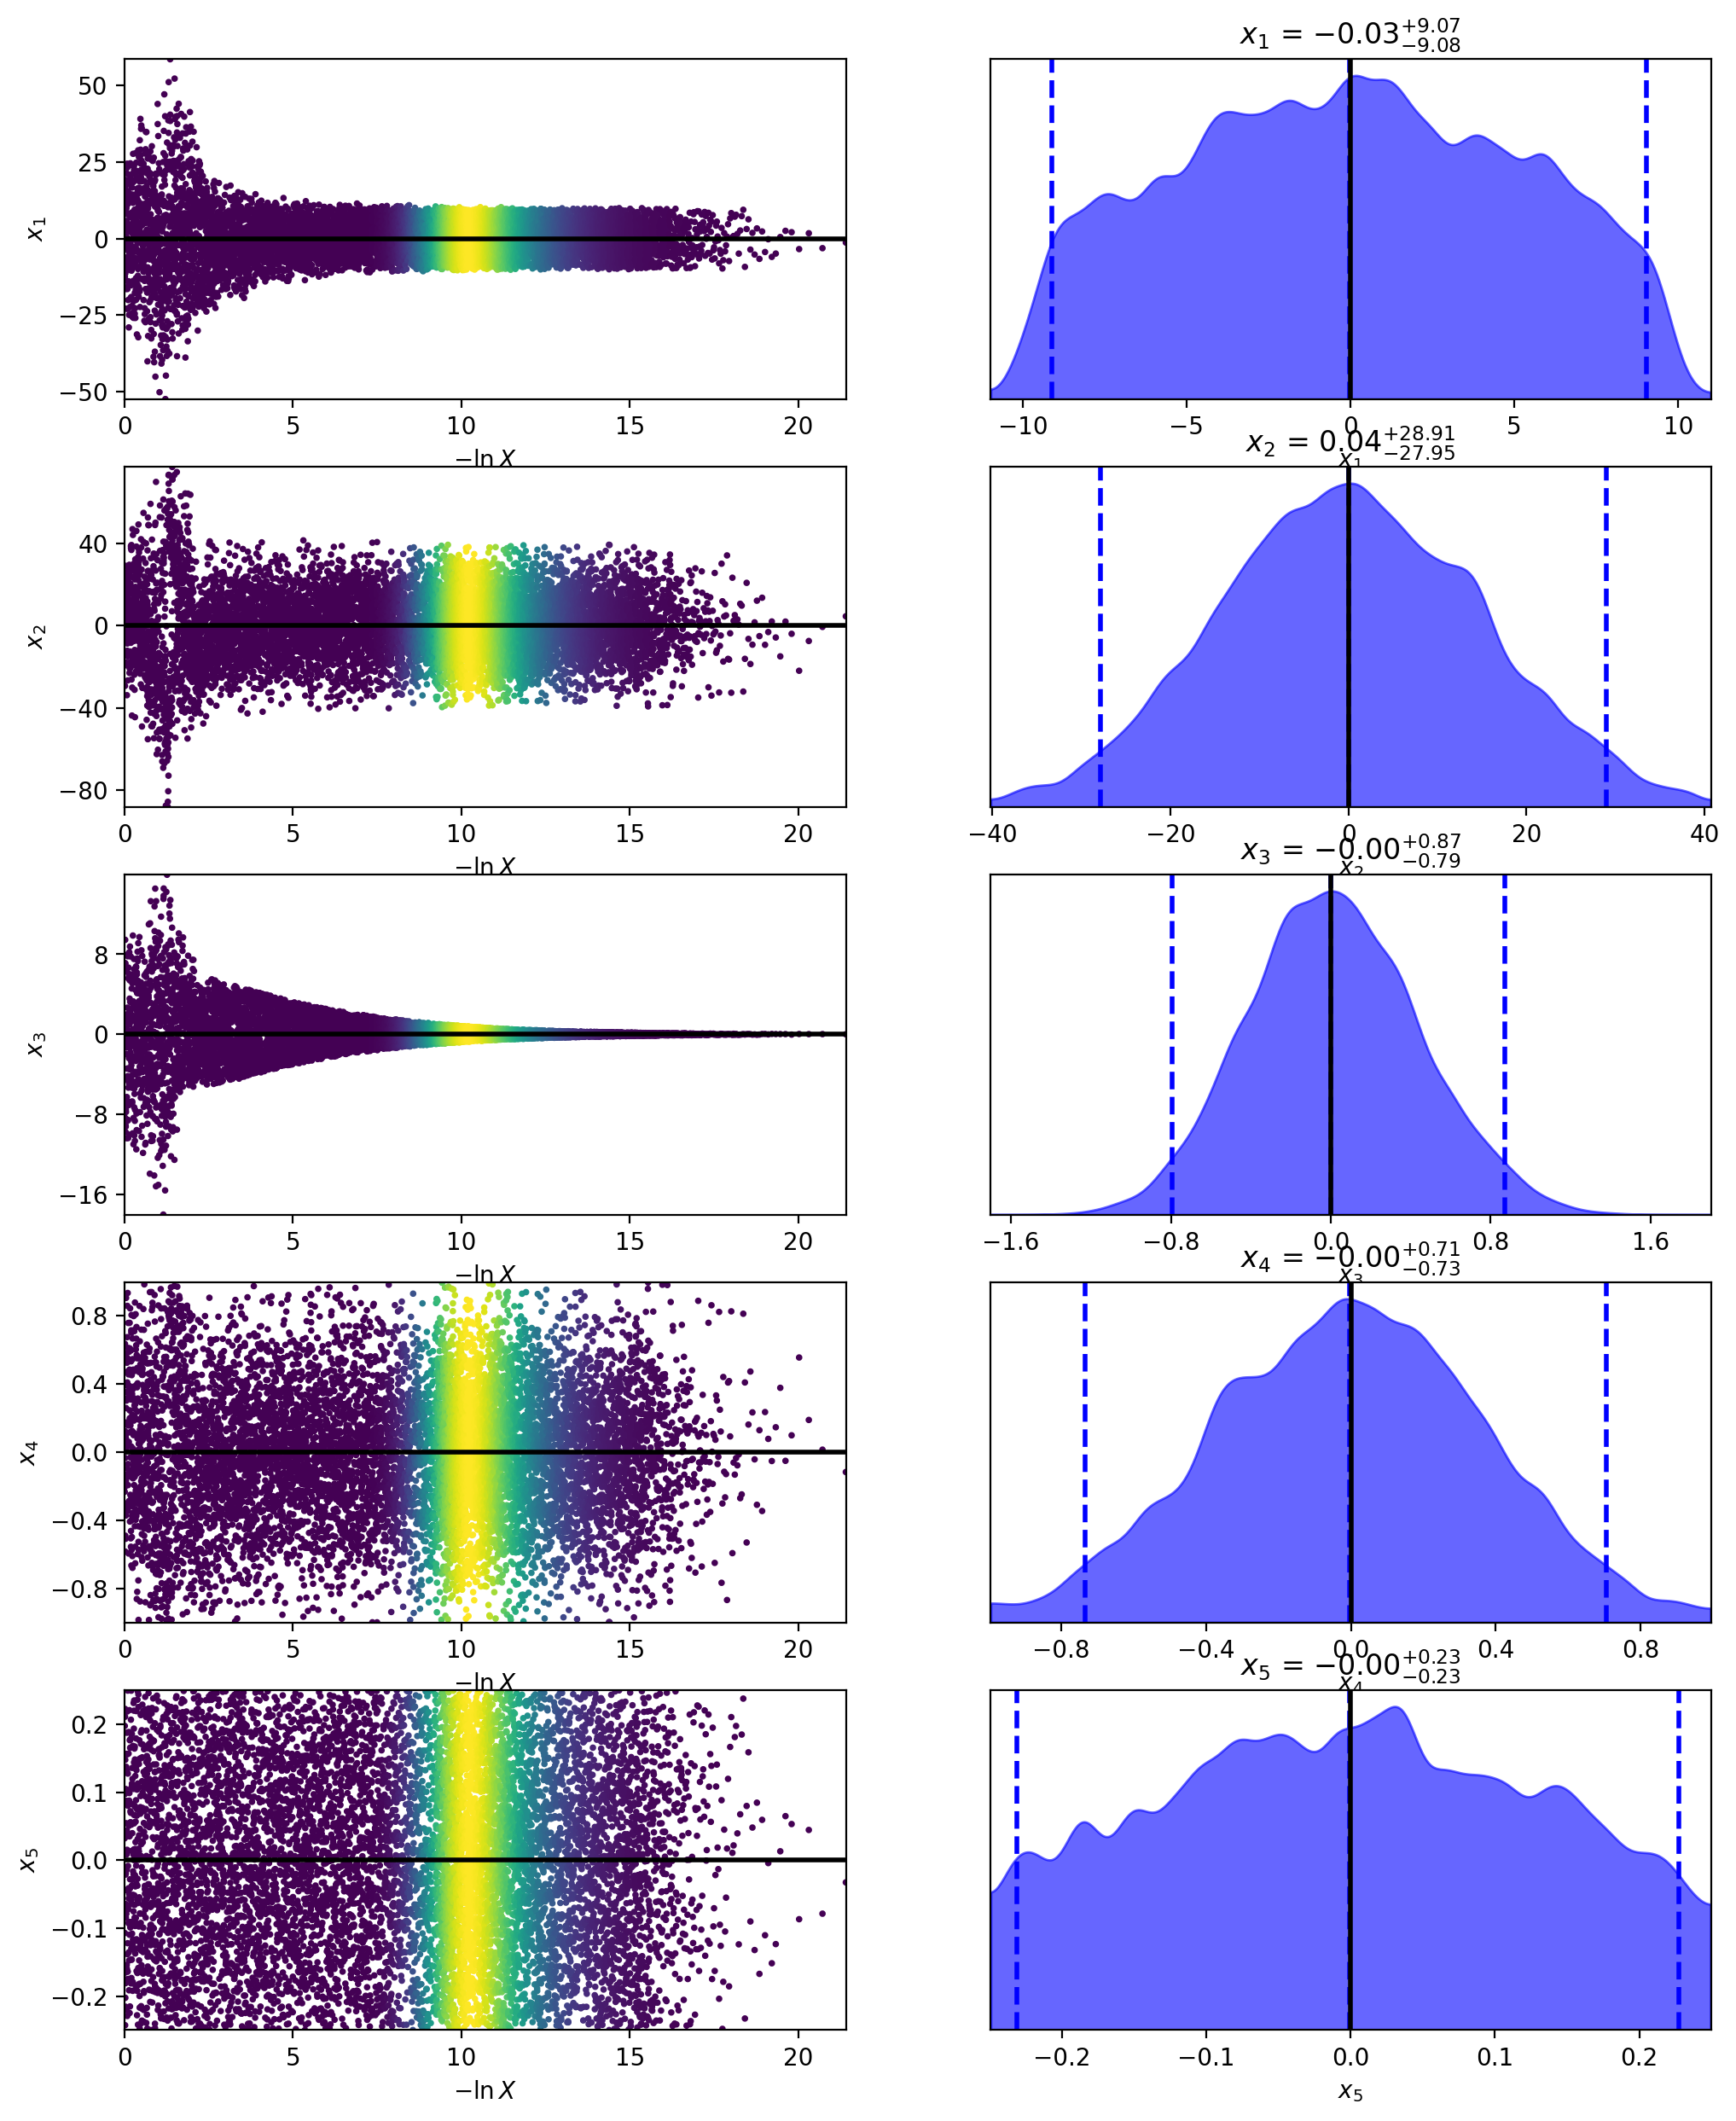

In [536]:
fig, axes = dyplot.traceplot(dres, truths=truths,
                             truth_color='black', show_titles=True,
                             trace_cmap='viridis')

In [605]:
"""t0 = np.array([np.percentile(dres.samples[:,0], 50, method="inverted_cdf", weights=dres.importance_weights()), np.percentile(dres.samples[:,1], 50, method="inverted_cdf", weights=dres.importance_weights()), np.percentile(dres.samples[:,2], 50, method="inverted_cdf", weights=dres.importance_weights()), np.percentile(dres.samples[:,3], 50, method="inverted_cdf", weights=dres.importance_weights()), np.percentile(dres.samples[:,4], 50, method="inverted_cdf", weights=dres.importance_weights())])"""

t0 = np.array([-0.03, 0.04, 0.00, 0.00, 0.00])

def lstep(t):
    return np.sum((genpsf(WL=650e-9, pdx=0, pdy=0, pdz=0, ptx=0, pty=0, dterms=10) - genpsf(WL=650e-9, pdx=t[0], pdy=t[1], pdz=t[2], ptx=t[3], pty=t[4], dterms=10))**2)

res = minimize(lstep, t0, method='Powell', options={'disp': True, 'ftol': 1e-10})
print(np.round(res.x, 3))

Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 5
         Function evaluations: 571
[ 0.001  0.     0.    -0.     0.   ]


In [606]:
res.x

array([ 7.84125560e-04,  4.39742693e-06,  1.55508346e-05, -1.54545908e-09,
        1.97572323e-05])

In [595]:
t0 = np.array([0.001, 0., -0., -0.,0.])

In [596]:
np.sum((genpsf(WL=650e-9, pdx=0, pdy=0, pdz=0, ptx=0, pty=0, dterms=10) - genpsf(WL=650e-9, pdx=t0[0], pdy=t0[1], pdz=t0[2], ptx=t0[3], pty=t0[4], dterms=10))**2)

np.float64(5.598521468697757e-13)

In [523]:
np.average(dres.samples[:,0], weights=dres.importance_weights())

np.float64(-0.4672623351916564)

In [516]:
dres.importance_weights()

array([0.        , 0.        , 0.        , ..., 0.00355281, 0.00356552,
       0.00359857], shape=(5501,))

Hubble

In [548]:
HST_data = {
    'M1': {
        'Radius': 11040.,
        'Conic': -1.0022985,
        'Aperture': 2 * 1200.,
        'Obscuration':{
            'Inner': 2 * 350.,
            'Arm size': 25.,
            'Arm number': 4
        }
    },
    'M2': {
        'Radius': 1358.,
        'Conic': -1.49600,
        'Aperture': 2 * 150.
    },
    'Spacings': {
        'BFD': 1500.,
        'Separation': 4906.072
    }
}

def hubble(WL, dx, dy, dz, tx, ty):
    #global WL
    global telescope, M1

    global outter1, inner1, outterD
    
    K = 1000 #meter to mm conversion
    M = 1000000 #m to micron conversion
    A = 3600 #degree to arcsec conversion
        ##############################

        ### Primary ###
    R1, conic1, inner1, outter1 = -HST_data['M1']['Radius']/K, HST_data['M1']['Conic'], HST_data['M1']['Obscuration']['Inner']/K, HST_data['M1']['Aperture']/K
    M1coord = defineCoordinate().local()
    M1 = optic('M1', type='Quadric', RoC=R1, conic=conic1, inDiam=inner1, outDiam=outter1, coordSys=M1coord).mirrorWithSpider(4, 0.025)
        ###############

        ### Seconday ###
    R2, conic2, outter2 = -HST_data['M2']['Radius']/K, HST_data['M2']['Conic'], HST_data['M2']['Aperture']/K
    pos2 = -HST_data['Spacings']['Separation']/K
    M2coord = defineCoordinate(posX=dx/M, posY=dy/M, posZ=pos2+dz/M, anglX=tx/A, anglY=ty/A).local()
    M2 = optic('M2', type='Quadric', RoC=R2, conic=conic2, outDiam=outter2, coordSys=M2coord).mirror()
        ################

        ### Detector ###
    outterD = 1
    posD = HST_data['Spacings']['BFD']/K
    Dcoord = defineCoordinate(posZ=posD).local()
    D = optic('D', outDiam=outterD, coordSys=Dcoord).detector()
        ################

        ### HST ###
    telescope = build.compoundOptic(M1, M2, D,
                                   pupilSize=outter1, backDist=6,
                                   EPcoord=defineCoordinate(posZ=0).local())
    
    return telescope

In [549]:
def hubblepsf(WL=650e-9, pdx=0, pdy=0, pdz=0, ptx=0, pty=0, dterms=5):

    telescope = hubble(WL, pdx, pdy, pdz, ptx, pty)
    infoTelescope = details(telescope, fieldX=0, fieldY=0.01389, wavelength=WL)
    PSF, _ = infoTelescope.fftPSF(npx=16, pad=2)
    r = decompose_psf(PSF, nterms=dterms, basis=basis_vectors)

    return r

vec_genpsf = np.frompyfunc(hubblepsf, 7, 1)

In [550]:
#Truth

pdx_true = 0
pdy_true = 0

## PSF 
ct = hubblepsf(WL=650e-9, pdx=pdx_true, pdy=pdy_true, dterms=3)


In [551]:
C = np.array([[ 2.23705947e-05, -3.84723886e-06, -2.84581347e-06],
              [-3.84723886e-06,  3.45412489e-06,  8.11232076e-07],
              [-2.84581347e-06,  8.11232076e-07,  3.11113256e-06]])
Cinv = np.linalg.inv(C)  # precision matrix
lnorm = -0.5 * (np.log(2 * np.pi) * 3 + np.log(np.linalg.det(C)))  # ln(normalization)

# log-likelihood
def loglike(theta):
    pdx,pdy = theta
    ## PSF
    c = hubblepsf(WL=650e-9, pdx=pdx, pdy=pdy, dterms=3)
    inv_sigma2 = 1.0 / (c**2)
    
    return -0.5 * np.dot(ct-c, np.dot(Cinv, ct-c)) + lnorm

# prior transform
def ptform(utheta):

    upx,upy = utheta

    mpx, spx = 0, 150  # mean and standard deviation
    lpx, hpx = -300, 300  # lower and upper bounds
    xpx = scipy.stats.truncnorm.ppf(upx, lpx, hpx, loc=mpx, scale=spx)

    mpy, spy = 0, 300  # mean and standard deviation
    lpy, hpy = -900, 900  # lower and upper bounds
    xpy = scipy.stats.truncnorm.ppf(upy, lpy, hpy, loc=mpy, scale=spy)

    return xpx,xpy

In [554]:
with dypool.Pool(8, loglike, ptform) as pool:

    dsampler = dynesty.DynamicNestedSampler(pool.loglike, pool.prior_transform, ndim=2, 
                                  sample='unif',pool=pool)
    dsampler.run_nested(maxiter=3000)
dres = dsampler.results

2999it [10:07, 21.15it/s, batch: 0 | bound: 4 | nc: 2 | ncall: 19115 | eff(%): 15.289 | loglstar:   -inf < 14.811 <    inf | logz:  9.467 +/-  0.090 | dlogz:  0.666 >  0.010] /opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/dynesty/sampler.py:1082: UserWarning: The sampling was stopped short due to maxiter/maxcall limit the delta(log(z)) criterion is not achieved; posterior may be poorly sampled
  warnings.warn('The sampling was stopped short due to'
3501it [10:07,  5.76it/s, batch: 0 | bound: 4 | nc: 1 | ncall: 19620 | eff(%): 17.844 | loglstar:   -inf < 15.400 <    inf | logz: 10.000 +/-  0.099 | dlogz:  0.001 >  0.010]


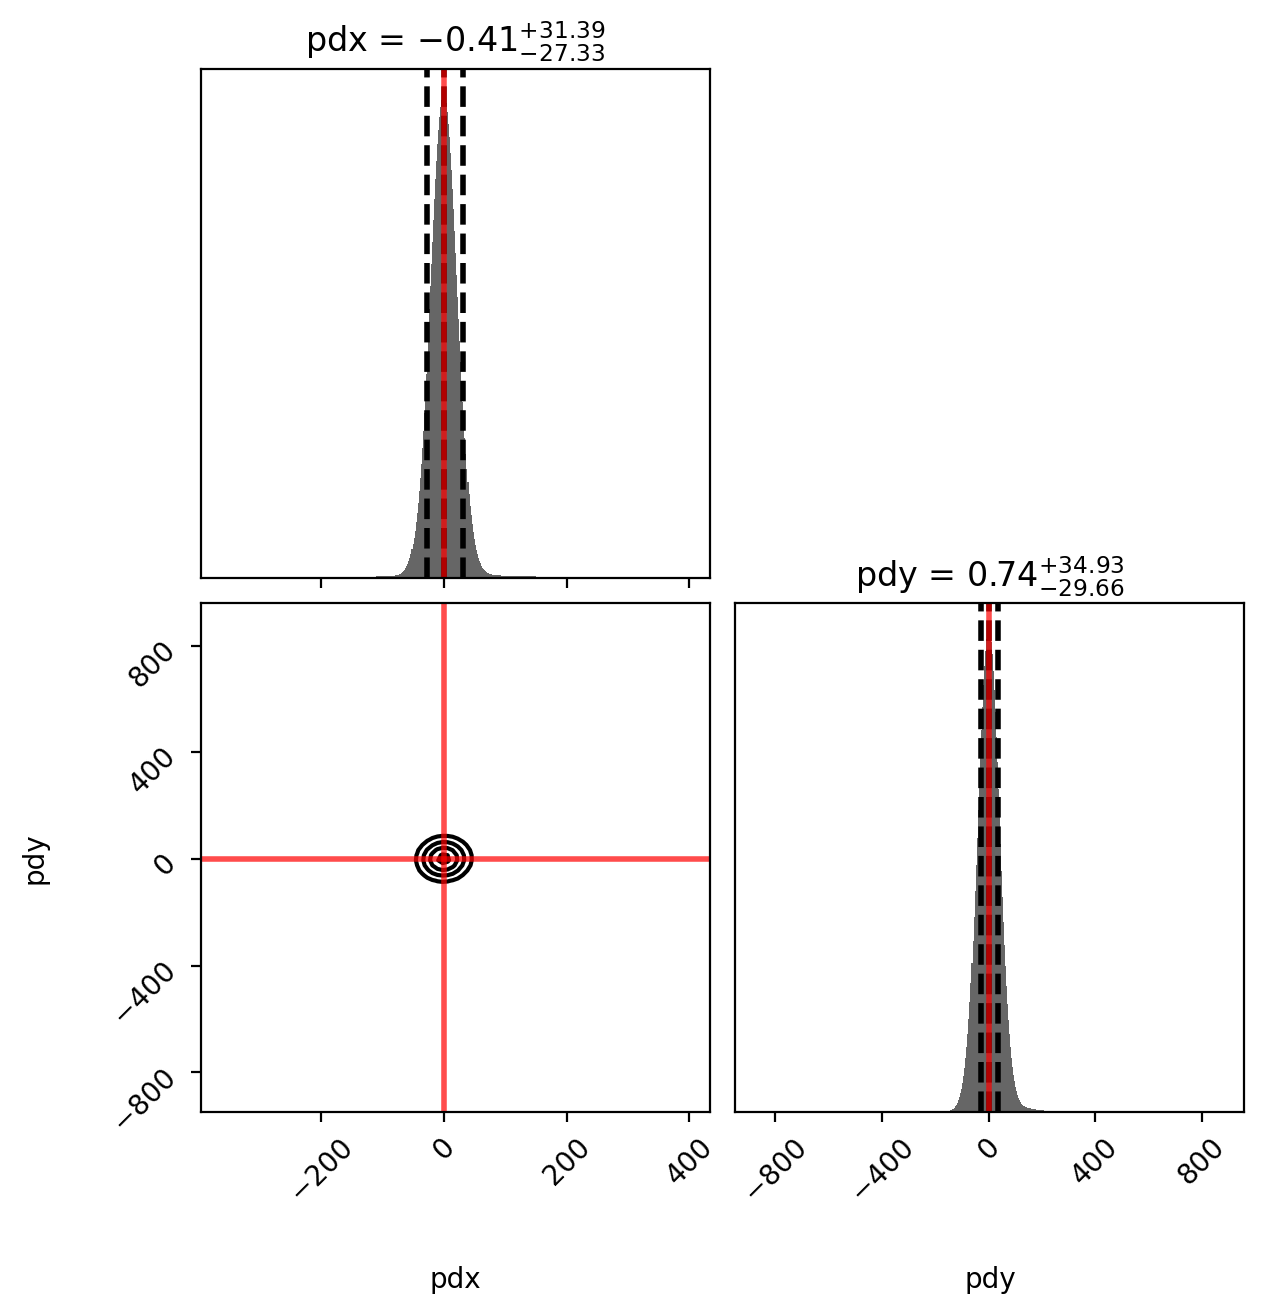

In [558]:
from dynesty import plotting as dyplot
plt.rcParams['text.usetex'] = False

labels = [r'pdx',r'pdy']
truths = [pdx_true,pdy_true]

fig, axes = dyplot.cornerplot(dres, truths=truths, show_titles=True, 
                               labels=labels, span = [1., 1.],
                              fig=plt.subplots(2, 2, figsize=(7, 7)))

In [560]:
t0

array([-0.41084643,  0.72909046])

In [562]:
dres = dsampler.results
t0 = np.array([np.percentile(dres.samples[:,0], 50, method="inverted_cdf", weights=dres.importance_weights()), np.percentile(dres.samples[:,1], 50, method="inverted_cdf", weights=dres.importance_weights())])

def lstep(t):
    return np.sum((hubblepsf(WL=650e-9, pdx=0, pdy=0, dterms=3) - hubblepsf(WL=650e-9, pdx=t[0], pdy=t[1], dterms=3))**2)

res = minimize(lstep, t0, method='Nelder-Mead', tol = 1e-6, options={'disp': True})
print(0,0,np.round(res.x, 3))

Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 58
         Function evaluations: 111
0 0 [ 0. -0.]
